# Лабораторная работа 1. Предсказание RiskScore — экспериментальная версия

Выполнил Колосов Егор Евгеньевич, группа М8О-312БВ-24

Предсказываю кредитный риск `RiskScore` по анкетным и финансовым данным заёмщиков.
Основная метрика — MSE, цель соревнования — MSE < 18.

В этой версии дополнительно проверяю модель со скрытыми группами риска.
Она состоит из нескольких линейных регрессий и уточнения меток групп.
Основное одноэтапное решение находится в соседней папке `lab1_regression`.

Файлы `train.csv`, `test.csv` и `ex.csv` находятся в папке `data`.
Путь задаётся в `DATA_DIR`. Ячейки нужно выполнить по порядку; в конце создаётся `submission.csv`.


In [1]:
from pathlib import Path
import os
import time
import itertools
import warnings

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display

# sklearn нужен только для проверки собственных реализаций
import sklearn
from sklearn.linear_model import LinearRegression as SkLinearRegression
from sklearn.linear_model import SGDRegressor, Ridge, Lasso, ElasticNet
from sklearn.preprocessing import StandardScaler as SkStandardScaler
from sklearn.preprocessing import MinMaxScaler as SkMinMaxScaler
from sklearn.metrics import (mean_squared_error, mean_absolute_error, r2_score,
                             mean_absolute_percentage_error)
from sklearn.model_selection import KFold, LeaveOneOut, cross_val_predict
from sklearn.pipeline import make_pipeline

from threadpoolctl import threadpool_limits
thread_limit = threadpool_limits(limits=1)

SEED = 42
TARGET = "RiskScore"

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)
pd.set_option("display.float_format", lambda v: f"{v:.4f}")
plt.rcParams.update({"figure.dpi": 100, "font.size": 10, "axes.grid": True, "grid.alpha": 0.3, "axes.titlesize": 10})

import platform
print("Python", platform.python_version(), "| numpy", np.__version__, "| pandas", pd.__version__,
      "| scikit-learn", sklearn.__version__, "| matplotlib", matplotlib.__version__)

Python 3.13.15 | numpy 2.5.4 | pandas 3.1.1 | scikit-learn 1.9.1 | matplotlib 3.11.2


## 1. Загрузка и проверка данных

Проверяю размеры таблиц, состав признаков, пропуски, повторы и распределение цели.
`ID` используется только для посылки. Значения в `ex.csv` служат примером формата.

In [2]:
DATA_DIR = Path('data')
paths = {name:DATA_DIR/f'{name}.csv' for name in ['train','test','ex']}
missing = [str(path) for path in paths.values() if not path.is_file()]
if missing:
    raise FileNotFoundError('Не найдены файлы: '+', '.join(missing))
train_raw = pd.read_csv(paths['train'])
test_raw = pd.read_csv(paths['test'])
example = pd.read_csv(paths['ex'])
for name,frame in [('train',train_raw),('test',test_raw),('ex',example)]:
    print(f'{name}: {frame.shape[0]} строк, {frame.shape[1]} столбцов')
FEATURE_COLS = [c for c in train_raw if c!=TARGET]
assert FEATURE_COLS==[c for c in test_raw if c!='ID']
assert test_raw.ID.equals(example.ID)
print('Состав и порядок признаков совпадают:',len(FEATURE_COLS))
display(train_raw.head())


train: 11017 строк, 35 столбцов
test: 5000 строк, 35 столбцов
ex: 5000 строк, 2 столбцов
Состав и порядок признаков совпадают: 34


,ApplicationDate,Age,AnnualIncome,CreditScore,LoanAmount,LoanDuration,MaritalStatus,NumberOfDependents,HomeOwnershipStatus,MonthlyDebtPayments,CreditCardUtilizationRate,NumberOfOpenCreditLines,NumberOfCreditInquiries,DebtToIncomeRatio,BankruptcyHistory,LoanPurpose,PreviousLoanDefaults,PaymentHistory,LengthOfCreditHistory,SavingsAccountBalance,CheckingAccountBalance,TotalAssets,TotalLiabilities,MonthlyIncome,UtilityBillsPaymentHistory,JobTenure,EmploymentStatus,EducationLevel,Experience,NetWorth,BaseInterestRate,InterestRate,MonthlyLoanPayment,TotalDebtToIncomeRatio,RiskScore
0,2010-06-26,27.0000,66829.0000,549.0000,17290.0000,60.0000,Divorced,1.0000,Rent,1095.0000,0.1520,2.0000,1.0000,0.1685,0.0000,Education,0.0000,23.0000,5.0000,2539.0000,247.0000,50072.0000,15005.0000,5569.0833,0.9083,4.0000,Employed,Associate,4.0000,35067.0000,0.2578,0.2515,508.9702,0.2880,66.1765
1,1996-09-23,55.0000,172147.0000,850.0000,16110.0000,36.0000,Widowed,1.0000,Mortgage,211.0000,0.1757,3.0000,0.0000,0.1416,0.0000,Home,0.0000,27.0000,11.0000,844.0000,694.0000,91878.0000,64877.0000,14345.5833,0.7973,2.0000,Employed,High School,33.0000,27001.0000,0.0861,0.0932,514.6759,0.0506,28.4957
2,2015-01-19,51.0000,300000.0000,850.0000,38436.0000,36.0000,Married,0.0000,Mortgage,546.0000,0.4446,3.0000,0.0000,0.0310,1.0000,Education,0.0000,21.0000,12.0000,12756.0000,651.0000,292300.0000,13918.0000,25000.0000,0.9159,3.0000,Employed,Bachelor,28.0000,278382.0000,0.1084,0.1154,1268.2764,0.0726,34.4881
3,1981-05-12,25.0000,34683.0000,847.0000,19186.0000,48.0000,Married,0.0000,Other,153.0000,0.1885,7.0000,0.0000,0.3798,0.0000,Debt Consolidation,0.0000,27.0000,21.0000,1524.0000,529.0000,13070.0000,3846.0000,2890.2500,0.8764,3.0000,Employed,High School,0.0000,9224.0000,0.1007,0.1128,498.5052,0.2254,36.9108
4,1995-05-07,55.0000,300000.0000,850.0000,30437.0000,48.0000,Single,2.0000,Rent,562.0000,0.2734,3.0000,1.0000,0.0687,0.0000,Debt Consolidation,0.0000,35.0000,9.0000,1973.0000,128.0000,33357.0000,351603.0000,25000.0000,0.8887,5.0000,Employed,Bachelor,31.0000,4502.0000,0.1104,0.0890,756.0352,0.0527,31.3471


In [3]:
overview = pd.DataFrame({
    "тип в train": train_raw.dtypes.astype(str),
    "тип в test": test_raw.dtypes.astype(str).reindex(train_raw.columns),
    "пропусков в train": train_raw.isna().sum(),
    "пропусков в test": test_raw.isna().sum().reindex(train_raw.columns),
    "уникальных в train": train_raw.nunique(),
})
display(overview)

,тип в train,тип в test,пропусков в train,пропусков в test,уникальных в train
ApplicationDate,str,str,530,0.0000,10000
Age,float64,int64,530,0.0000,63
AnnualIncome,float64,int64,530,0.0000,5602
CreditScore,float64,int64,1031,0.0000,548
LoanAmount,float64,int64,1031,0.0000,8720
LoanDuration,float64,int64,530,0.0000,10
MaritalStatus,str,str,530,0.0000,4
NumberOfDependents,float64,int64,530,0.0000,7
HomeOwnershipStatus,str,str,530,0.0000,4
MonthlyDebtPayments,float64,int64,1031,0.0000,1736


In [4]:
# --- пропуски
empty_rows = train_raw.isna().all(axis=1)
partial_rows = train_raw.isna().any(axis=1) & ~empty_rows
partial_cols = train_raw.columns[train_raw[partial_rows].isna().any()].tolist()
print("Полностью пустых строк:", int(empty_rows.sum()))
print("Строк с частичными пропусками:", int(partial_rows.sum()))
print("  столбцы с пропусками в этих строках:", partial_cols)
print("  во всех таких строках пропущен один и тот же набор столбцов:",
      bool(train_raw.loc[partial_rows, partial_cols].isna().all().all()))
print("Пропусков в test:", int(test_raw.isna().sum().sum()))

# --- дубликаты
non_empty = train_raw[~empty_rows]
print("\nПолных дубликатов строк (лишних копий):", int(non_empty.duplicated().sum()))
print("Дубликатов по одним только признакам:   ", int(non_empty.duplicated(subset=FEATURE_COLS).sum()),
      "(одинаковые признаки всегда идут с одинаковой целью)")
print("Дубликатов строк в test (без ID):", int(test_raw.drop(columns="ID").duplicated().sum()))
feature_overlap = test_raw.merge(non_empty.drop_duplicates(subset=FEATURE_COLS), on=FEATURE_COLS, how="inner")
print("Строк test, совпадающих по признакам со строками train:", len(feature_overlap))

# --- целевая переменная
print("\nОписательная статистика исходной цели:")
print(train_raw[TARGET].describe().to_string())
bad_target = non_empty[TARGET].abs() > 1000
print("\nЗначений цели вне разумного диапазона:", int(bad_target.sum()),
      dict(non_empty.loc[bad_target, TARGET].value_counts()))

# --- идентификаторы
print("\nID в test:", test_raw["ID"].min(), "...", test_raw["ID"].max(), "| уникальны:", test_raw["ID"].is_unique)
print("ID в ex.csv совпадают с ID в test.csv (и по порядку):", bool((example["ID"].values == test_raw["ID"].values).all()))

Полностью пустых строк: 530
Строк с частичными пропусками: 501
  столбцы с пропусками в этих строках: ['CreditScore', 'LoanAmount', 'MonthlyDebtPayments', 'BankruptcyHistory', 'LoanPurpose', 'CheckingAccountBalance', 'TotalAssets', 'NetWorth', 'BaseInterestRate']
  во всех таких строках пропущен один и тот же набор столбцов: True
Пропусков в test: 0

Полных дубликатов строк (лишних копий): 487
Дубликатов по одним только признакам:    487 (одинаковые признаки всегда идут с одинаковой целью)


Дубликатов строк в test (без ID): 0
Строк test, совпадающих по признакам со строками train: 0

Описательная статистика исходной цели:
count      10487.0000
mean      -25698.7837
std      1431674.5904
min     -9999999.0000
25%           32.5647
50%           44.1188
75%           65.3569
max     10000000.0000

Значений цели вне разумного диапазона: 215 {-9999999.0: np.int64(121), 10000000.0: np.int64(94)}

ID в test: 0 ... 4999 | уникальны: True
ID в ex.csv совпадают с ID в test.csv (и по порядку): True


### Первичная проверка

В train и test совпадают 34 входных столбца. В обучающей таблице есть 530 пустых строк,
487 точных повторов и заглушки цели. В 456 строках после очистки остаётся общий блок пропусков.
В тестовой таблице пропусков нет.

### Очистка данных

Удаляю пустые строки, заглушки цели и точные повторы. В этой версии для обучения оставляю
9 332 полные строки. Ниже отдельно сравниваю этот вариант с заполнением пропусков
медианами и модами обучающей части. Идентификаторы тестовых строк сохраняются.

In [5]:
def clean_train(frame, drop_partial=True):
    """Очистка обучающей таблицы по правилам 1-4."""
    out = frame[~frame.isna().all(axis=1)]
    out = out[out[TARGET].between(0, 100)]
    out = out.drop_duplicates()
    if drop_partial:
        out = out.dropna()
    return out.reset_index(drop=True)


train = clean_train(train_raw)                                  # полные строки
train_with_gaps = clean_train(train_raw, drop_partial=False)
train_gaps_only = train_with_gaps[train_with_gaps.isna().any(axis=1)].reset_index(drop=True)

print("Исходных строк:                 ", len(train_raw))
print("После правил 1-3:               ", len(train_with_gaps))
print("  из них с блоком пропусков:    ", len(train_gaps_only))
print("Итоговая обучающая таблица:     ", len(train), "строк")
print("Диапазон цели после очистки:    ", round(train[TARGET].min(), 3), "...", round(train[TARGET].max(), 3))

CAT_COLS = ["MaritalStatus", "HomeOwnershipStatus", "LoanPurpose", "EmploymentStatus", "EducationLevel"]
DATE_COL = "ApplicationDate"
NUM_COLS = [c for c in FEATURE_COLS if c not in CAT_COLS + [DATE_COL]]
print("\nЧисловых признаков:", len(NUM_COLS), "| категориальных:", len(CAT_COLS), "| дата:", DATE_COL)

Исходных строк:                  11017
После правил 1-3:                9788
  из них с блоком пропусков:     456
Итоговая обучающая таблица:      9332 строк
Диапазон цели после очистки:     14.841 ... 97.597

Числовых признаков: 28 | категориальных: 5 | дата: ApplicationDate


## 2. Разведочный анализ данных

### 2.1. Целевая переменная

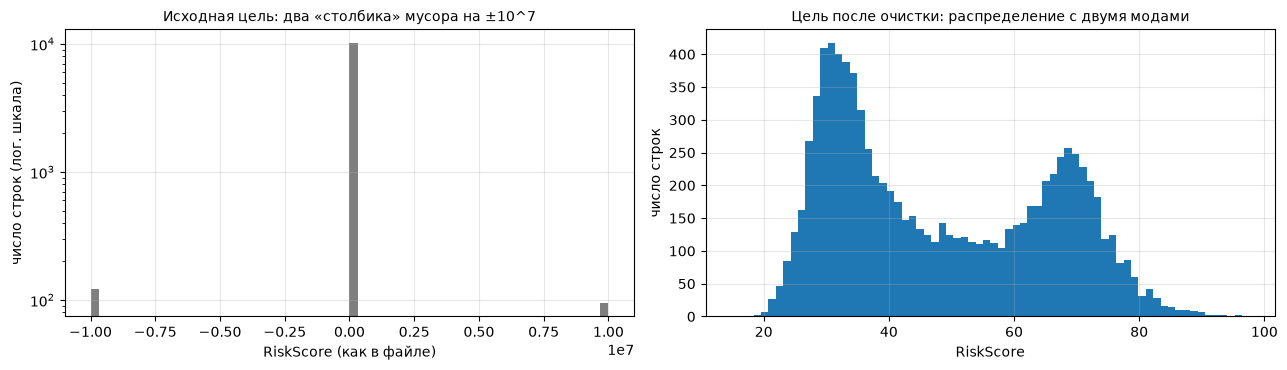

count   9332.0000
mean      48.3125
std       17.2431
min       14.8414
25%       32.6933
50%       44.1275
75%       65.0594
max       97.5972

Минимум цели: 14.841 - нулевых и близких к нулю значений нет, значит MAPE определена и устойчива.


In [6]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ax[0].hist(train_raw[TARGET].dropna(), bins=60, color="tab:gray")
ax[0].set_yscale("log")
ax[0].set_title("Исходная цель: два «столбика» мусора на ±10^7")
ax[0].set_xlabel("RiskScore (как в файле)")
ax[0].set_ylabel("число строк (лог. шкала)")
ax[1].hist(train[TARGET], bins=70, color="tab:blue")
ax[1].set_title("Цель после очистки: распределение с двумя модами")
ax[1].set_xlabel("RiskScore")
ax[1].set_ylabel("число строк")
plt.tight_layout()
plt.show()

print(train[TARGET].describe().to_string())
print("\nМинимум цели:", round(train[TARGET].min(), 3),
      "- нулевых и близких к нулю значений нет, значит MAPE определена и устойчива.")

### 2.2. Числовые признаки: статистики и «упоры» в границы

In [7]:
display(train[NUM_COLS].describe().T)

print("Доля строк, в которых значение стоит ровно на границе диапазона:")
for col, borders in {"AnnualIncome": [15000, 300000], "MonthlyIncome": [1250, 25000], "CreditScore": [300, 850]}.items():
    shares = ", ".join(f"{b}: {np.mean(train[col] == b):.1%} (test {np.mean(test_raw[col] == b):.1%})" for b in borders)
    print(f"  {col:14s} {shares}")

,count,mean,std,min,25%,50%,75%,max
Age,9332.0000,39.8812,11.5859,18.0000,32.0000,40.0000,48.0000,80.0000
AnnualIncome,9332.0000,131643.6142,116023.0449,15000.0000,21030.5000,88961.5000,257499.7500,748508.0000
CreditScore,9332.0000,678.0692,175.2144,300.0000,550.0000,723.0000,850.0000,850.0000
LoanAmount,9332.0000,29806.5415,27314.5485,1063.0000,12632.7500,21814.0000,37173.5000,418997.0000
LoanDuration,9332.0000,53.3828,24.4151,12.0000,36.0000,48.0000,60.0000,120.0000
NumberOfDependents,9332.0000,1.5667,1.4178,0.0000,0.0000,1.0000,3.0000,6.0000
MonthlyDebtPayments,9332.0000,546.9320,503.4171,13.0000,234.0000,399.0000,686.0000,10879.0000
CreditCardUtilizationRate,9332.0000,0.2850,0.1594,0.0037,0.1596,0.2634,0.3917,0.9146
NumberOfOpenCreditLines,9332.0000,3.0312,1.7399,0.0000,2.0000,3.0000,4.0000,12.0000
NumberOfCreditInquiries,9332.0000,0.9797,0.9879,0.0000,0.0000,1.0000,2.0000,6.0000


Доля строк, в которых значение стоит ровно на границе диапазона:
  AnnualIncome   15000: 22.3% (test 22.1%), 300000: 21.3% (test 21.7%)
  MonthlyIncome  1250: 22.5% (test 22.2%), 25000: 21.6% (test 21.9%)
  CreditScore    300: 4.8% (test 4.5%), 850: 31.0% (test 31.5%)


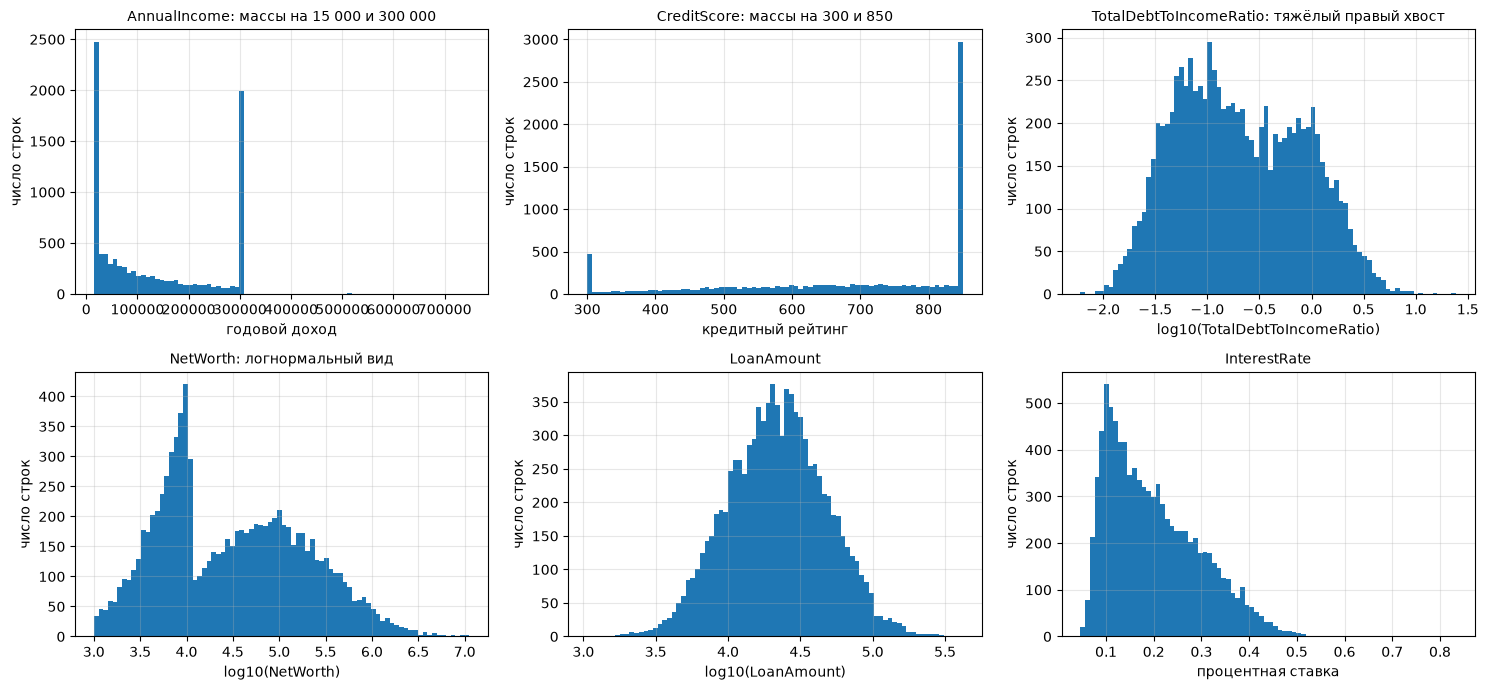

In [8]:
fig, ax = plt.subplots(2, 3, figsize=(15, 7))
ax[0, 0].hist(train["AnnualIncome"], bins=80)
ax[0, 0].set_title("AnnualIncome: массы на 15 000 и 300 000")
ax[0, 0].set_xlabel("годовой доход")
ax[0, 1].hist(train["CreditScore"], bins=80)
ax[0, 1].set_title("CreditScore: массы на 300 и 850")
ax[0, 1].set_xlabel("кредитный рейтинг")
ax[0, 2].hist(np.log10(train["TotalDebtToIncomeRatio"]), bins=80)
ax[0, 2].set_title("TotalDebtToIncomeRatio: тяжёлый правый хвост")
ax[0, 2].set_xlabel("log10(TotalDebtToIncomeRatio)")
ax[1, 0].hist(np.log10(train["NetWorth"]), bins=80)
ax[1, 0].set_title("NetWorth: логнормальный вид")
ax[1, 0].set_xlabel("log10(NetWorth)")
ax[1, 1].hist(np.log10(train["LoanAmount"]), bins=80)
ax[1, 1].set_title("LoanAmount")
ax[1, 1].set_xlabel("log10(LoanAmount)")
ax[1, 2].hist(train["InterestRate"], bins=80)
ax[1, 2].set_title("InterestRate")
ax[1, 2].set_xlabel("процентная ставка")
for a in ax.ravel():
    a.set_ylabel("число строк")
plt.tight_layout()
plt.show()

### 2.3. Зависимости признаков друг от друга

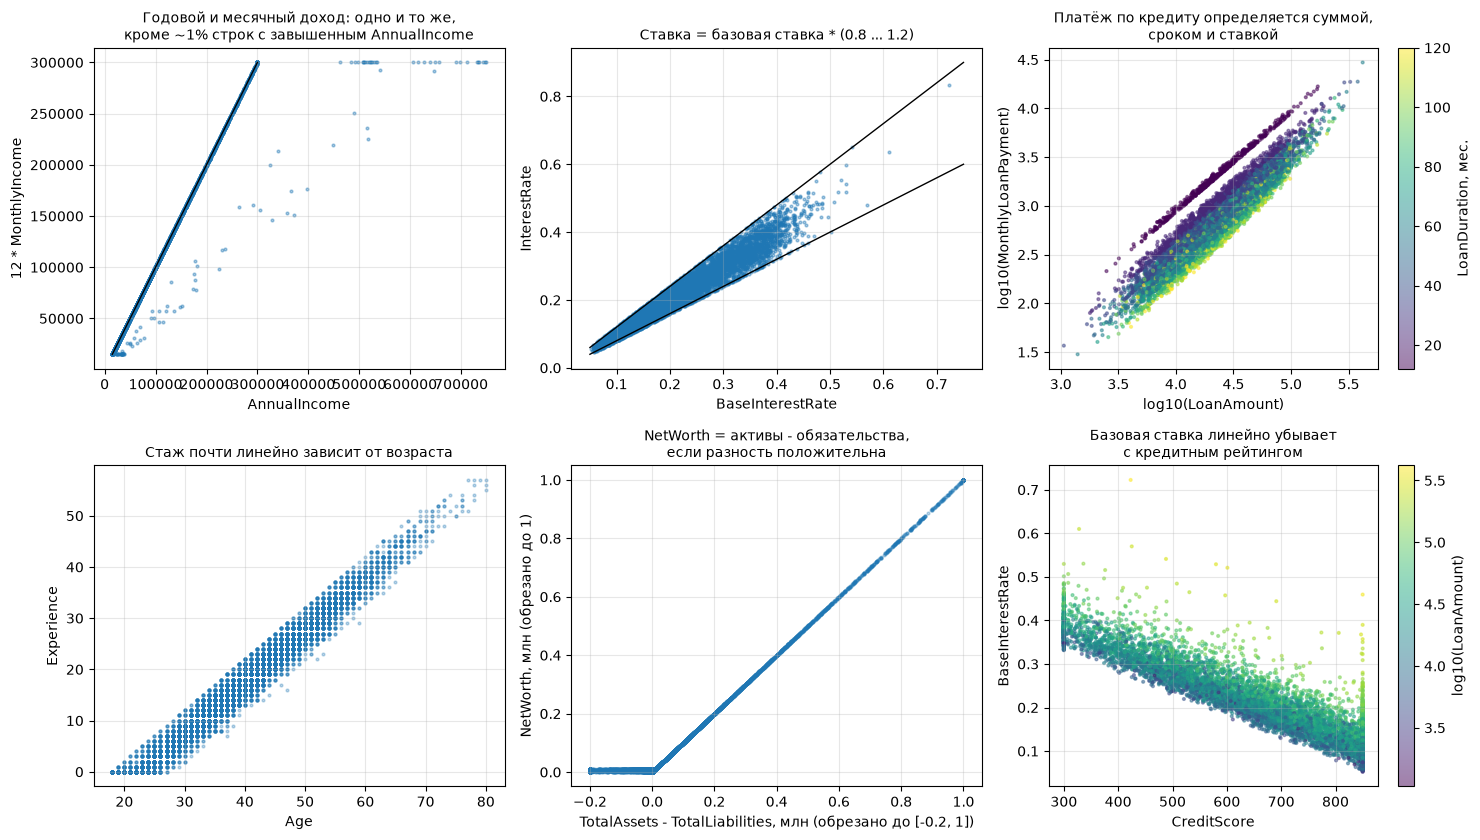

In [9]:
fig, ax = plt.subplots(2, 3, figsize=(15, 8.5))

ax[0, 0].scatter(train["AnnualIncome"], 12 * train["MonthlyIncome"], s=4, alpha=0.4)
ax[0, 0].plot([15000, 300000], [15000, 300000], color="k", lw=1)
ax[0, 0].set_xlabel("AnnualIncome")
ax[0, 0].set_ylabel("12 * MonthlyIncome")
ax[0, 0].set_title("Годовой и месячный доход: одно и то же,\nкроме ~1% строк с завышенным AnnualIncome")

ax[0, 1].scatter(train["BaseInterestRate"], train["InterestRate"], s=4, alpha=0.4)
grid = np.array([0.05, 0.75])
for k in (0.8, 1.2):
    ax[0, 1].plot(grid, k * grid, color="k", lw=1)
ax[0, 1].set_xlabel("BaseInterestRate")
ax[0, 1].set_ylabel("InterestRate")
ax[0, 1].set_title("Ставка = базовая ставка * (0.8 ... 1.2)")

sc = ax[0, 2].scatter(np.log10(train["LoanAmount"]), np.log10(train["MonthlyLoanPayment"]), c=train["LoanDuration"], s=4, alpha=0.5, cmap="viridis")
fig.colorbar(sc, ax=ax[0, 2], label="LoanDuration, мес.")
ax[0, 2].set_xlabel("log10(LoanAmount)")
ax[0, 2].set_ylabel("log10(MonthlyLoanPayment)")
ax[0, 2].set_title("Платёж по кредиту определяется суммой,\nсроком и ставкой")

ax[1, 0].scatter(train["Age"], train["Experience"], s=4, alpha=0.3)
ax[1, 0].set_xlabel("Age")
ax[1, 0].set_ylabel("Experience")
ax[1, 0].set_title("Стаж почти линейно зависит от возраста")

equity = ((train["TotalAssets"] - train["TotalLiabilities"]) / 1e6).clip(-0.2, 1.0)
ax[1, 1].scatter(equity, (train["NetWorth"] / 1e6).clip(upper=1.0), s=4, alpha=0.3)
ax[1, 1].set_xlabel("TotalAssets - TotalLiabilities, млн (обрезано до [-0.2, 1])")
ax[1, 1].set_ylabel("NetWorth, млн (обрезано до 1)")
ax[1, 1].set_title("NetWorth = активы - обязательства,\nесли разность положительна")

sc = ax[1, 2].scatter(train["CreditScore"], train["BaseInterestRate"], c=np.log10(train["LoanAmount"]), s=4, alpha=0.5, cmap="viridis")
fig.colorbar(sc, ax=ax[1, 2], label="log10(LoanAmount)")
ax[1, 2].set_xlabel("CreditScore")
ax[1, 2].set_ylabel("BaseInterestRate")
ax[1, 2].set_title("Базовая ставка линейно убывает\nс кредитным рейтингом")

plt.tight_layout()
plt.show()

In [10]:
# Проверка точных связей между признаками (это свойства данных, цель здесь не участвует)
r = train["InterestRate"] / 12
n_months = train["LoanDuration"]
annuity = train["LoanAmount"] * r * (1 + r) ** n_months / ((1 + r) ** n_months - 1)
print("MonthlyLoanPayment = аннуитетный платёж: макс. относительное отклонение",
      f"{np.max(np.abs(train['MonthlyLoanPayment'] / annuity - 1)):.1e}")

total_dti = (train["MonthlyDebtPayments"] + train["MonthlyLoanPayment"]) / train["MonthlyIncome"]
print("TotalDebtToIncomeRatio = (MonthlyDebtPayments + MonthlyLoanPayment) / MonthlyIncome: макс. отклонение",
      f"{np.max(np.abs(train['TotalDebtToIncomeRatio'] - total_dti)):.1e}")

A = np.column_stack([np.ones(len(train)), train[["CreditScore", "LoanAmount", "LoanDuration"]].to_numpy(float)])
coef, *_ = np.linalg.lstsq(A, train["BaseInterestRate"].to_numpy(float), rcond=None)
resid = train["BaseInterestRate"].to_numpy(float) - A @ coef
print("BaseInterestRate = a + b*CreditScore + c*LoanAmount + d*LoanDuration: коэффициенты",
      np.array2string(coef, precision=8), "| макс. остаток", f"{np.max(np.abs(resid)):.1e}")

print("Доля строк, где MonthlyIncome = AnnualIncome / 12:",
      f"{np.mean(np.isclose(train['MonthlyIncome'], train['AnnualIncome'] / 12)):.3f}")
print("Доля строк, где NetWorth = TotalAssets - TotalLiabilities:",
      f"{np.mean(np.isclose(train['NetWorth'], train['TotalAssets'] - train['TotalLiabilities'])):.3f}")

# BaseInterestRate не несёт новой информации: это точная линейная комбинация трёх других признаков
REDUNDANT_COLS = ["BaseInterestRate"]
MODEL_NUM_COLS = [c for c in NUM_COLS if c not in REDUNDANT_COLS]
print("\nЧисловых признаков для моделей:", len(MODEL_NUM_COLS), "(исключён", REDUNDANT_COLS[0] + ")")

MonthlyLoanPayment = аннуитетный платёж: макс. относительное отклонение 3.5e-14
TotalDebtToIncomeRatio = (MonthlyDebtPayments + MonthlyLoanPayment) / MonthlyIncome: макс. отклонение 1.8e-15
BaseInterestRate = a + b*CreditScore + c*LoanAmount + d*LoanDuration: коэффициенты [ 4.65000000e-01 -5.00000000e-04  1.00000000e-06  8.33333333e-04] | макс. остаток 1.3e-14
Доля строк, где MonthlyIncome = AnnualIncome / 12: 0.989
Доля строк, где NetWorth = TotalAssets - TotalLiabilities: 0.688

Числовых признаков для моделей: 27 (исключён BaseInterestRate)


**Следствие для линейной регрессии.** `BaseInterestRate` — точная линейная комбинация `CreditScore`, `LoanAmount` и `LoanDuration`.
Если оставить его среди признаков, матрица признаков будет иметь неполный ранг, матрица $X^\top X$ станет вырожденной,
а коэффициенты МНК — неоднозначными. Признак-дубликат поэтому исключается из моделей (качество от этого не меняется: предсказания МНК
зависят только от линейной оболочки признаков). Что именно происходит, если его оставить, показано в разделе 5.4.

Остальные зависимости (`TotalDebtToIncomeRatio`, `MonthlyLoanPayment`, пара `AnnualIncome`/`MonthlyIncome`) нелинейные или неточные,
поэтому эти признаки остаются: они несут информацию, которую линейная модель сама из исходных столбцов получить не может.

### 2.4. Матрица корреляций

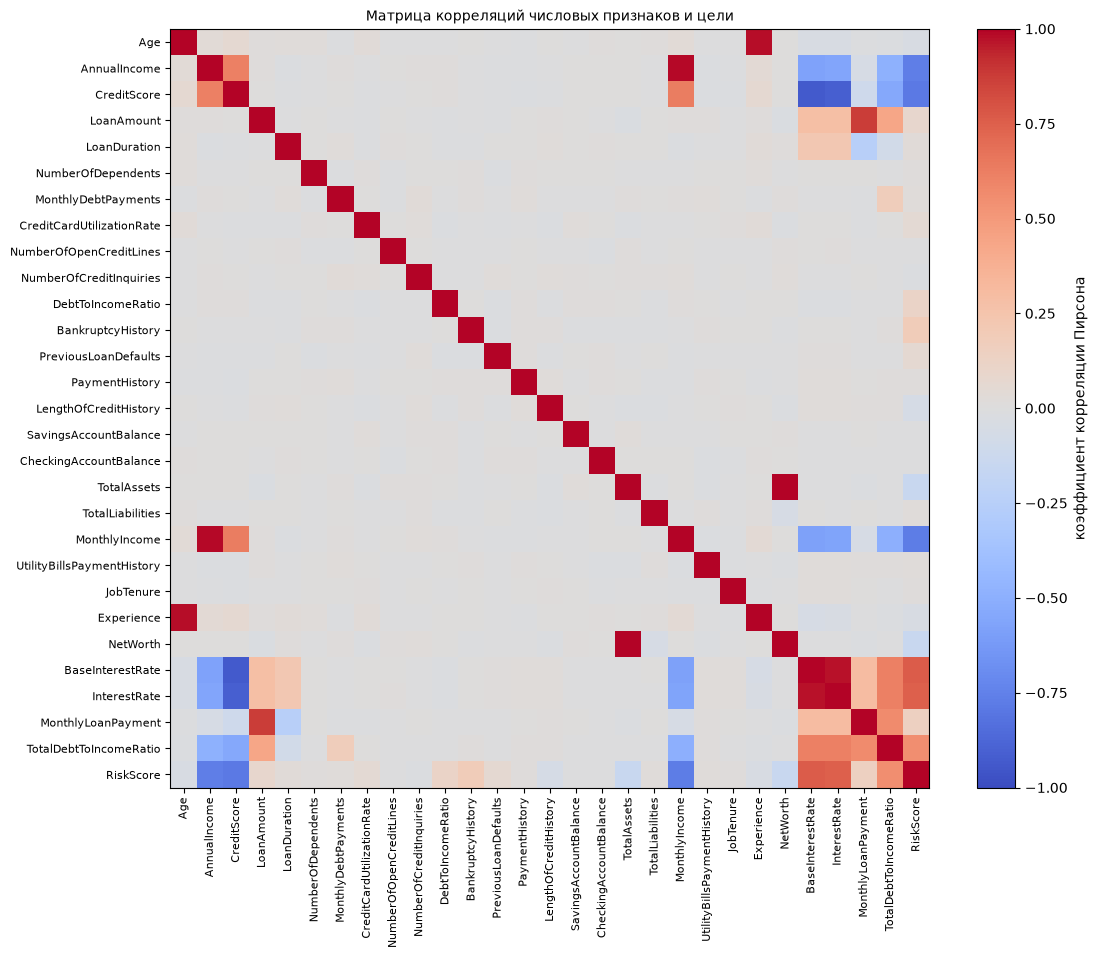

Пары признаков с |r| > 0.9:
  TotalAssets                NetWorth                   +0.994
  AnnualIncome               MonthlyIncome              +0.984
  Age                        Experience                 +0.983
  BaseInterestRate           InterestRate               +0.975
  CreditScore                BaseInterestRate           -0.933
  CreditScore                InterestRate               -0.909

Связь числовых признаков с целью (первые 12 по модулю корреляции Спирмена):


,Пирсон,Спирмен
MonthlyIncome,-0.7703,-0.8159
AnnualIncome,-0.7579,-0.8147
TotalDebtToIncomeRatio,0.5544,0.7815
CreditScore,-0.7854,-0.7655
BaseInterestRate,0.7595,0.7453
InterestRate,0.7442,0.7357
MonthlyLoanPayment,0.1474,0.1936
TotalAssets,-0.1475,-0.1827
NetWorth,-0.1462,-0.1827
BankruptcyHistory,0.1797,0.1730


In [11]:
corr = train[NUM_COLS + [TARGET]].corr()
fig, ax = plt.subplots(figsize=(11.5, 9.5))
im = ax.imshow(corr.values, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)))
ax.set_yticks(range(len(corr)))
ax.set_xticklabels(corr.columns, rotation=90, fontsize=8)
ax.set_yticklabels(corr.columns, fontsize=8)
ax.grid(False)
fig.colorbar(im, ax=ax, label="коэффициент корреляции Пирсона")
ax.set_title("Матрица корреляций числовых признаков и цели")
plt.tight_layout()
plt.show()

pairs = [(a, b, corr.loc[a, b]) for a, b in itertools.combinations(NUM_COLS, 2) if abs(corr.loc[a, b]) > 0.9]
print("Пары признаков с |r| > 0.9:")
for a, b, value in sorted(pairs, key=lambda t: -abs(t[2])):
    print(f"  {a:26s} {b:26s} {value:+.3f}")

target_corr = pd.DataFrame({
    "Пирсон": train[NUM_COLS].corrwith(train[TARGET]),
    "Спирмен": train[NUM_COLS].corrwith(train[TARGET], method="spearman"),
}).sort_values("Спирмен", key=np.abs, ascending=False)
print("\nСвязь числовых признаков с целью (первые 12 по модулю корреляции Спирмена):")
display(target_corr.head(12))

### 2.5. Цель и основные признаки

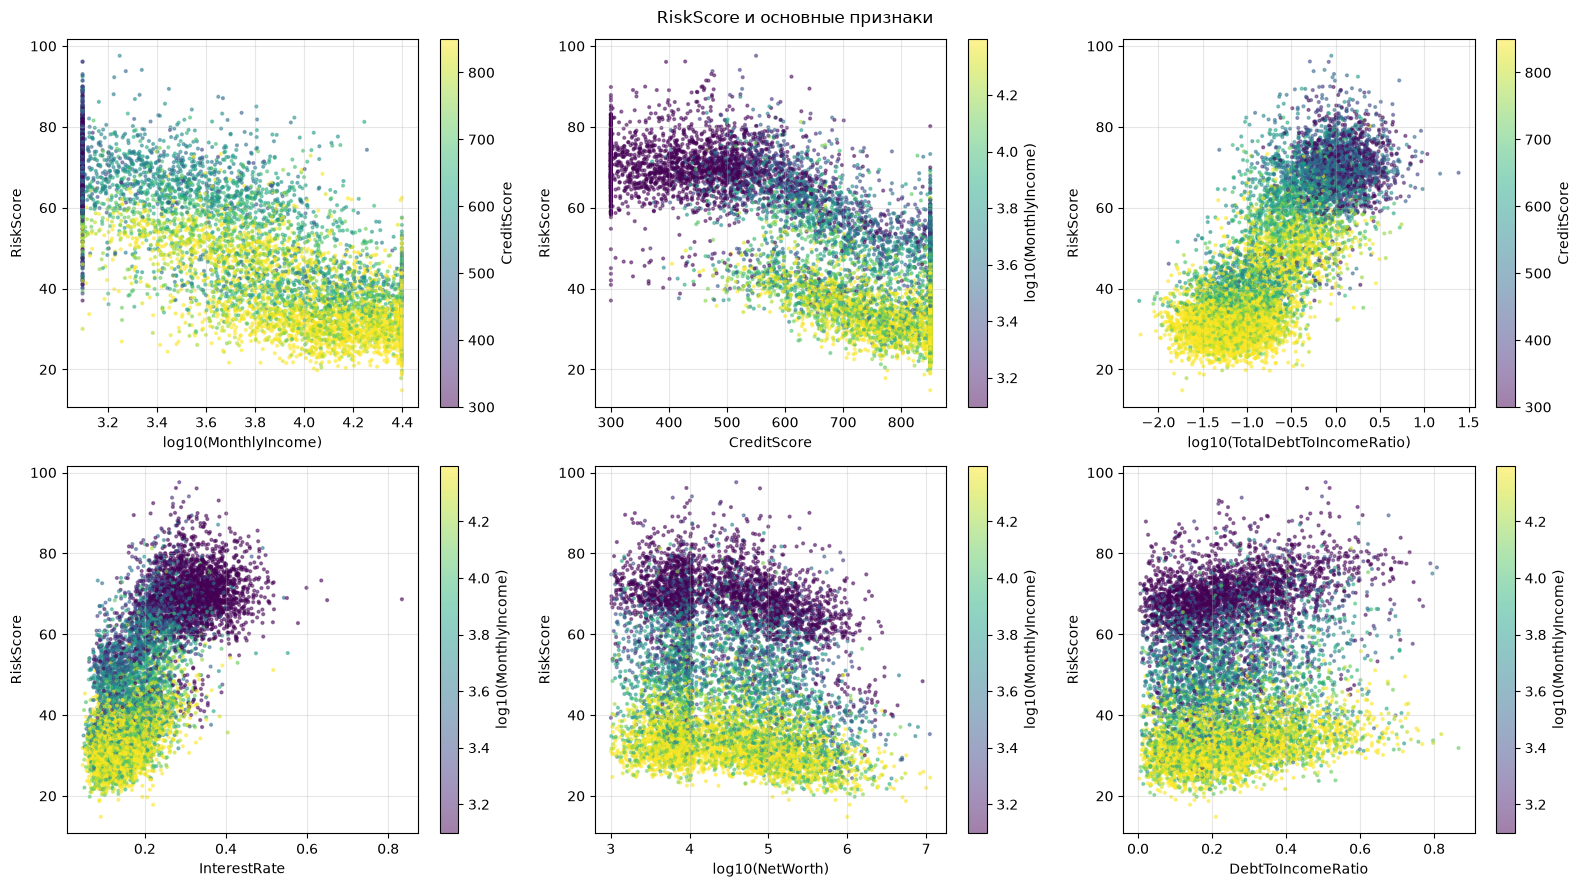

In [12]:
log_income = np.log10(train["MonthlyIncome"])
fig, ax = plt.subplots(2, 3, figsize=(16, 9))

sc = ax[0, 0].scatter(log_income, train[TARGET], c=train["CreditScore"], s=4, alpha=0.5, cmap="viridis")
fig.colorbar(sc, ax=ax[0, 0], label="CreditScore")
ax[0, 0].set_xlabel("log10(MonthlyIncome)")

sc = ax[0, 1].scatter(train["CreditScore"], train[TARGET], c=log_income, s=4, alpha=0.5, cmap="viridis")
fig.colorbar(sc, ax=ax[0, 1], label="log10(MonthlyIncome)")
ax[0, 1].set_xlabel("CreditScore")

sc = ax[0, 2].scatter(np.log10(train["TotalDebtToIncomeRatio"]), train[TARGET], c=train["CreditScore"], s=4, alpha=0.5, cmap="viridis")
fig.colorbar(sc, ax=ax[0, 2], label="CreditScore")
ax[0, 2].set_xlabel("log10(TotalDebtToIncomeRatio)")

sc = ax[1, 0].scatter(train["InterestRate"], train[TARGET], c=log_income, s=4, alpha=0.5, cmap="viridis")
fig.colorbar(sc, ax=ax[1, 0], label="log10(MonthlyIncome)")
ax[1, 0].set_xlabel("InterestRate")

sc = ax[1, 1].scatter(np.log10(train["NetWorth"]), train[TARGET], c=log_income, s=4, alpha=0.5, cmap="viridis")
fig.colorbar(sc, ax=ax[1, 1], label="log10(MonthlyIncome)")
ax[1, 1].set_xlabel("log10(NetWorth)")

sc = ax[1, 2].scatter(train["DebtToIncomeRatio"], train[TARGET], c=log_income, s=4, alpha=0.5, cmap="viridis")
fig.colorbar(sc, ax=ax[1, 2], label="log10(MonthlyIncome)")
ax[1, 2].set_xlabel("DebtToIncomeRatio")

for a in ax.ravel():
    a.set_ylabel("RiskScore")
fig.suptitle("RiskScore и основные признаки", fontsize=12)
plt.tight_layout()
plt.show()

### 2.6. Категориальные признаки, бинарные признаки и дата

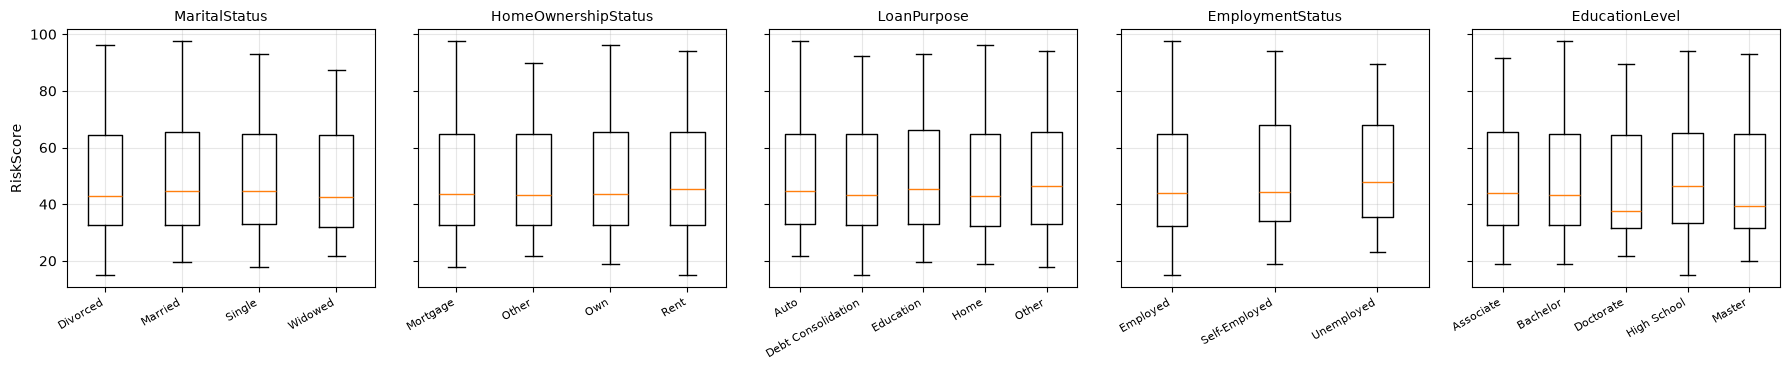

                     mean     std  count
BankruptcyHistory                       
0                 47.5900 16.8600   8845
1                 61.5200 18.6700    487 

                        mean     std  count
PreviousLoanDefaults                       
0                    48.0000 17.2100   8434
1                    51.2300 17.2600    898 

                    mean     std  count
EmploymentStatus                       
Employed         47.9800 17.1400   8074
Self-Employed    49.9900 17.7800    877
Unemployed       51.5000 17.5900    381 

                  mean     std  count
EducationLevel                       
Associate      48.2100 17.2500   1836
Bachelor       48.0800 17.2400   2751
Doctorate      46.0200 17.9000    310
High School    49.0200 17.0600   3758
Master         46.6700 17.7500    677 

Категории в test, которых нет в train: {'MaritalStatus': [], 'HomeOwnershipStatus': [], 'LoanPurpose': [], 'EmploymentStatus': [], 'EducationLevel': []}


In [13]:
fig, ax = plt.subplots(1, 5, figsize=(18, 3.8), sharey=True)
for a, col in zip(ax, CAT_COLS):
    levels = sorted(train[col].unique())
    a.boxplot([train.loc[train[col] == lv, TARGET] for lv in levels], showfliers=False)
    a.set_xticks(range(1, len(levels) + 1))
    a.set_xticklabels(levels, rotation=30, ha="right", fontsize=8)
    a.set_title(col)
ax[0].set_ylabel("RiskScore")
plt.tight_layout()
plt.show()

for col in ["BankruptcyHistory", "PreviousLoanDefaults", "EmploymentStatus", "EducationLevel"]:
    key = train[col].astype(int) if col in NUM_COLS else train[col]
    print(train.groupby(key)[TARGET].agg(["mean", "std", "count"]).round(2).to_string(), "\n")

print("Категории в test, которых нет в train:",
      {col: sorted(set(test_raw[col]) - set(train[col])) for col in CAT_COLS})

Даты в train: 1979-01-01 ... 2020-01-25 | уникальных: 9332 из 9332


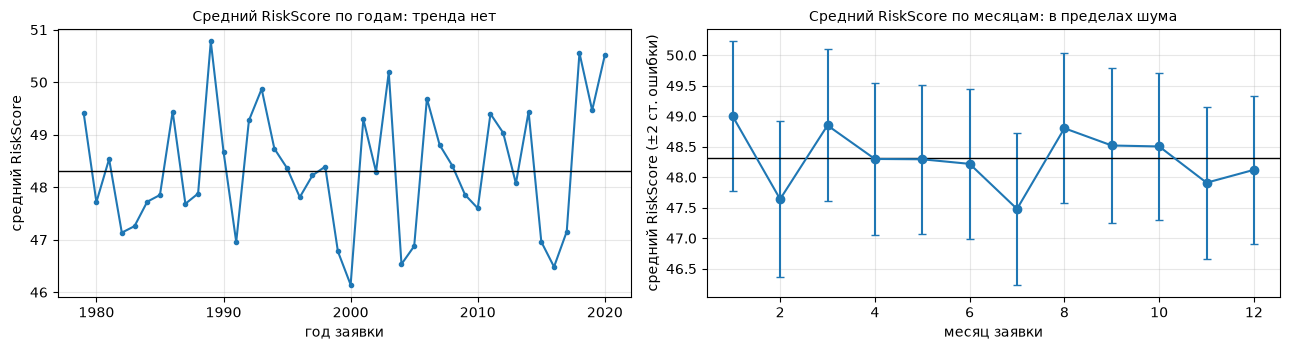

In [14]:
dates = pd.to_datetime(train[DATE_COL])
print("Даты в train:", dates.min().date(), "...", dates.max().date(), "| уникальных:", dates.nunique(), "из", len(dates))
by_year = train.groupby(dates.dt.year)[TARGET].mean()
by_month = train.groupby(dates.dt.month)[TARGET].agg(["mean", "sem"])

fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
ax[0].plot(by_year.index, by_year.values, marker="o", ms=3)
ax[0].axhline(train[TARGET].mean(), color="k", lw=1)
ax[0].set_xlabel("год заявки")
ax[0].set_ylabel("средний RiskScore")
ax[0].set_title("Средний RiskScore по годам: тренда нет")
ax[1].errorbar(by_month.index, by_month["mean"], yerr=2 * by_month["sem"], marker="o", capsize=3)
ax[1].axhline(train[TARGET].mean(), color="k", lw=1)
ax[1].set_xlabel("месяц заявки")
ax[1].set_ylabel("средний RiskScore (±2 ст. ошибки)")
ax[1].set_title("Средний RiskScore по месяцам: в пределах шума")
plt.tight_layout()
plt.show()

### 2.7. Два «режима» целевой переменной

Распределение цели двугорбое. Чтобы понять, откуда берутся два горба, посмотрим на подвыборки, где основные признаки зафиксированы.

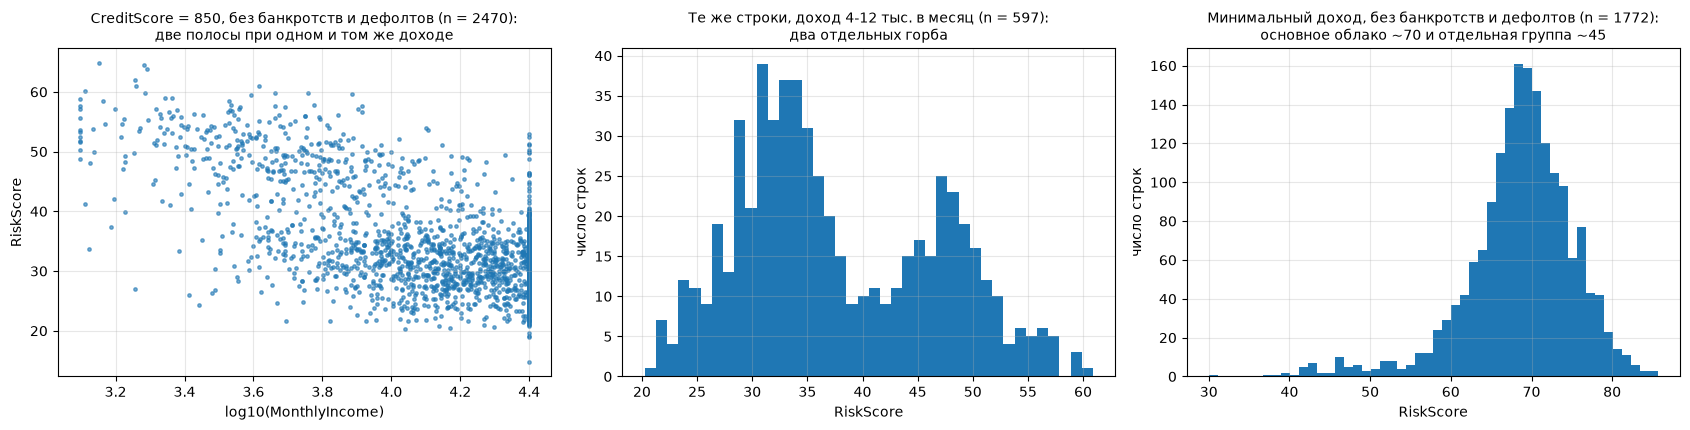

In [15]:
calm = (train["BankruptcyHistory"] == 0) & (train["PreviousLoanDefaults"] == 0)
top_score = train[calm & (train["CreditScore"] == 850)]
low_income = train[calm & (train["MonthlyIncome"] == 1250)]
mid_slice = top_score[(top_score["MonthlyIncome"] > 4000) & (top_score["MonthlyIncome"] < 12000)]

fig, ax = plt.subplots(1, 3, figsize=(17, 4.4))
ax[0].scatter(np.log10(top_score["MonthlyIncome"]), top_score[TARGET], s=6, alpha=0.6)
ax[0].set_xlabel("log10(MonthlyIncome)")
ax[0].set_ylabel("RiskScore")
ax[0].set_title(f"CreditScore = 850, без банкротств и дефолтов (n = {len(top_score)}):\nдве полосы при одном и том же доходе")

ax[1].hist(mid_slice[TARGET], bins=40)
ax[1].set_xlabel("RiskScore")
ax[1].set_ylabel("число строк")
ax[1].set_title(f"Те же строки, доход 4-12 тыс. в месяц (n = {len(mid_slice)}):\nдва отдельных горба")

ax[2].hist(low_income[TARGET], bins=50)
ax[2].set_xlabel("RiskScore")
ax[2].set_ylabel("число строк")
ax[2].set_title(f"Минимальный доход, без банкротств и дефолтов (n = {len(low_income)}):\nосновное облако ~70 и отдельная группа ~45")
plt.tight_layout()
plt.show()

### Выводы EDA

1. У цели два выраженных максимума, около 30 и 68. Это повод проверить модель с двумя группами риска.
2. Денежные показатели имеют длинные правые хвосты и сильно различаются по масштабу. Проверяю логарифмы и нормализацию.
3. Годовой и месячный доходы, возраст и стаж, активы и капитал тесно связаны. Такие связи затрудняют интерпретацию отдельных коэффициентов.
4. `BaseInterestRate` точно выражается через другие столбцы. Исключаю его из базовой модели.
5. Полезность даты проверяю по кросс-валидации. Сам по себе график двух облаков не доказывает наличие неизмеримого случайного фактора.

## 3. Метрики

Для $n$ наблюдений с истинными значениями $y_i$ и предсказаниями $\hat y_i$:

$$\mathrm{MSE} = \frac1n\sum_{i=1}^n (y_i - \hat y_i)^2, \qquad
\mathrm{MAE} = \frac1n\sum_{i=1}^n |y_i - \hat y_i|,$$

$$R^2 = 1 - \frac{\sum_i (y_i - \hat y_i)^2}{\sum_i (y_i - \bar y)^2}, \qquad
\mathrm{MAPE} = \frac1n\sum_{i=1}^n \frac{|y_i - \hat y_i|}{\max(|y_i|, \varepsilon)}.$$

Соглашения:

* MSE — именно средний квадрат ошибки, без корня. Регуляризационный штраф в MSE не входит.
* MAPE возвращается **долей**, а не в процентах (как в `sklearn`); $\varepsilon$ — машинный эпсилон, он защищает от деления на ноль.
  При $y_i = 0$ значение становится огромным — это свойство самой метрики. В нашей задаче $\min y \approx 15$, поэтому MAPE устойчива.
* $R^2$: если истинные значения постоянны, знаменатель равен нулю; тогда возвращается 1 при идеальном предсказании и 0 иначе
  (так же поступает `sklearn`). При $n < 2$ метрика не определена — возвращается `nan`.

In [16]:
def _as_pair(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float).ravel()
    y_pred = np.asarray(y_pred, dtype=float).ravel()
    if y_true.shape != y_pred.shape:
        raise ValueError("y_true и y_pred должны быть одной длины")
    if y_true.size == 0:
        raise ValueError("пустые массивы")
    return y_true, y_pred


def mse(y_true, y_pred):
    y_true, y_pred = _as_pair(y_true, y_pred)
    return float(np.mean((y_true - y_pred) ** 2))


def mae(y_true, y_pred):
    y_true, y_pred = _as_pair(y_true, y_pred)
    return float(np.mean(np.abs(y_true - y_pred)))


def r2(y_true, y_pred):
    y_true, y_pred = _as_pair(y_true, y_pred)
    if y_true.size < 2:
        return float("nan")
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - y_true.mean()) ** 2)
    if ss_tot == 0:
        return 1.0 if ss_res == 0 else 0.0
    return float(1.0 - ss_res / ss_tot)


def mape(y_true, y_pred):
    y_true, y_pred = _as_pair(y_true, y_pred)
    eps = np.finfo(float).eps
    return float(np.mean(np.abs(y_true - y_pred) / np.maximum(np.abs(y_true), eps)))


def all_metrics(y_true, y_pred):
    return {"MSE": mse(y_true, y_pred), "MAE": mae(y_true, y_pred), "R2": r2(y_true, y_pred), "MAPE": mape(y_true, y_pred)}

In [17]:
# 1) Небольшой пример с ответами, посчитанными вручную
yt = [3.0, -0.5, 2.0, 7.0]
yp = [2.5, 0.0, 2.0, 8.0]
# ошибки: 0.5, -0.5, 0, -1  ->  MSE = (0.25 + 0.25 + 0 + 1) / 4 = 0.375,  MAE = (0.5 + 0.5 + 0 + 1) / 4 = 0.5
# среднее y = 2.875, сумма квадратов отклонений = 29.1875  ->  R2 = 1 - 1.5 / 29.1875
# MAPE = (0.5/3 + 0.5/0.5 + 0 + 1/7) / 4
assert np.isclose(mse(yt, yp), 0.375)
assert np.isclose(mae(yt, yp), 0.5)
assert np.isclose(r2(yt, yp), 1 - 1.5 / 29.1875)
assert np.isclose(mape(yt, yp), (0.5 / 3 + 1.0 + 0.0 + 1 / 7) / 4)

# 2) Граничные случаи
assert mse(yt, yt) == 0 and mae(yt, yt) == 0 and r2(yt, yt) == 1 and mape(yt, yt) == 0      # идеальное предсказание
assert np.isclose(r2(yt, [np.mean(yt)] * 4), 0.0)                                            # предсказание средним -> R2 = 0
assert r2([5, 5, 5], [5, 5, 5]) == 1.0 and r2([5, 5, 5], [4, 5, 6]) == 0.0                   # постоянная цель
assert np.isnan(r2([1.0], [2.0]))                                                            # одно наблюдение
print("MAPE при нулевом истинном значении:", f"{mape([0.0, 1.0], [0.5, 1.0]):.3e}", "- огромное число, метрика в таком случае неприменима")

# 3) Сравнение со sklearn на случайных данных
rng = np.random.default_rng(SEED)
a = rng.normal(50, 17, size=1000)
b = a + rng.normal(0, 5, size=1000)
check = pd.DataFrame({
    "собственная": all_metrics(a, b),
    "sklearn": {"MSE": mean_squared_error(a, b), "MAE": mean_absolute_error(a, b), "R2": r2_score(a, b),
                "MAPE": mean_absolute_percentage_error(a, b)},
})
check["|разность|"] = (check["собственная"] - check["sklearn"]).abs()
pd.set_option("display.float_format", lambda v: f"{v:.10g}")
display(check)
pd.set_option("display.float_format", lambda v: f"{v:.4f}")
assert (check["|разность|"] < 1e-9).all()
print("Все проверки метрик пройдены. Те же метрики сравниваются со sklearn на реальных предсказаниях в разделе 5.")

MAPE при нулевом истинном значении: 1.126e+15 - огромное число, метрика в таком случае неприменима


,собственная,sklearn,|разность|
MSE,25.87219715,25.87219715,0
MAE,4.037102583,4.037102583,0
R2,0.9084229263,0.9084229263,0
MAPE,0.1257045653,0.1257045653,0


Все проверки метрик пройдены. Те же метрики сравниваются со sklearn на реальных предсказаниях в разделе 5.


## 4. Нормализация

$$z = \frac{x - \mu}{\sigma}, \qquad x' = \frac{x - x_{\min}}{x_{\max} - x_{\min}}$$

* Параметры ($\mu$, $\sigma$, $x_{\min}$, $x_{\max}$) оцениваются методом `fit` только по обучающей части и сохраняются;
  `transform` применяет их к любым данным.
* Стандартное отклонение считается со знаменателем $n$ (`ddof=0`) — так же, как в `sklearn.preprocessing.StandardScaler`,
  с которым реализация сравнивается ниже.
* Константный столбец: $\sigma = 0$ (или $x_{\max} = x_{\min}$). Делить на ноль нельзя, поэтому масштаб такого столбца принимается
  равным 1, и после вычитания среднего (минимума) столбец состоит из нулей.

In [18]:
class ZScoreScaler:
    """z = (x - mean) / std, параметры оцениваются в fit и применяются в transform."""

    def fit(self, X):
        X = np.asarray(X, dtype=float)
        self.mean_ = X.mean(axis=0)
        std = X.std(axis=0)                                  # знаменатель n (ddof=0)
        constant = std <= 1e-12 * np.maximum(1.0, np.abs(self.mean_))
        self.scale_ = np.where(constant, 1.0, std)
        return self

    def transform(self, X):
        return (np.asarray(X, dtype=float) - self.mean_) / self.scale_

    def fit_transform(self, X):
        return self.fit(X).transform(X)

    def inverse_transform(self, Z):
        return np.asarray(Z, dtype=float) * self.scale_ + self.mean_


class MinMaxScaler01:
    """x' = (x - min) / (max - min), параметры оцениваются в fit и применяются в transform."""

    def fit(self, X):
        X = np.asarray(X, dtype=float)
        self.min_ = X.min(axis=0)
        span = X.max(axis=0) - self.min_
        self.range_ = np.where(span <= 0, 1.0, span)
        return self

    def transform(self, X):
        return (np.asarray(X, dtype=float) - self.min_) / self.range_

    def fit_transform(self, X):
        return self.fit(X).transform(X)

    def inverse_transform(self, Z):
        return np.asarray(Z, dtype=float) * self.range_ + self.min_


def split_indices(n, val_share=0.2, random_state=None):
    """Случайное разбиение индексов 0..n-1 на обучающую и отложенную части."""
    order = np.random.default_rng(random_state).permutation(n)
    n_val = int(round(n * val_share))
    return np.sort(order[n_val:]), np.sort(order[:n_val])

In [19]:
# Демонстрация на реальных данных: параметры оцениваются по обучающей части, применяются к отложенной
demo_tr, demo_va = split_indices(len(train), 0.2, SEED)
X_demo = train[NUM_COLS].to_numpy(float)
X_demo = np.column_stack([X_demo, np.full(len(train), 7.0)])           # добавлен константный столбец для проверки
demo_names = NUM_COLS + ["константа"]

z = ZScoreScaler().fit(X_demo[demo_tr])
mm = MinMaxScaler01().fit(X_demo[demo_tr])
Z_tr, Z_va = z.transform(X_demo[demo_tr]), z.transform(X_demo[demo_va])
M_tr, M_va = mm.transform(X_demo[demo_tr]), mm.transform(X_demo[demo_va])

show = ["AnnualIncome", "CreditScore", "TotalDebtToIncomeRatio", "NetWorth", "InterestRate", "константа"]
idx = [demo_names.index(c) for c in show]
table = pd.DataFrame({
    "исходное среднее": X_demo[demo_tr][:, idx].mean(0),
    "исходное ст. откл.": X_demo[demo_tr][:, idx].std(0),
    "z: среднее (train)": Z_tr[:, idx].mean(0),
    "z: ст. откл. (train)": Z_tr[:, idx].std(0),
    "z: среднее (val)": Z_va[:, idx].mean(0),
    "min-max: min (train)": M_tr[:, idx].min(0),
    "min-max: max (train)": M_tr[:, idx].max(0),
    "min-max: max (val)": M_va[:, idx].max(0),
}, index=show)
display(table)

# Проверка через sklearn
sk_z = SkStandardScaler().fit(X_demo[demo_tr])
sk_mm = SkMinMaxScaler().fit(X_demo[demo_tr])
print("z-score:  макс. расхождение со StandardScaler на train / val:",
      f"{np.max(np.abs(Z_tr - sk_z.transform(X_demo[demo_tr]))):.2e} / {np.max(np.abs(Z_va - sk_z.transform(X_demo[demo_va]))):.2e}")
print("min-max:  макс. расхождение с MinMaxScaler на train / val:  ",
      f"{np.max(np.abs(M_tr - sk_mm.transform(X_demo[demo_tr]))):.2e} / {np.max(np.abs(M_va - sk_mm.transform(X_demo[demo_va]))):.2e}")
print("обратное преобразование восстанавливает данные:",
      np.allclose(z.inverse_transform(Z_va), X_demo[demo_va]), np.allclose(mm.inverse_transform(M_va), X_demo[demo_va]))
print("константный столбец после z-score и min-max:", np.unique(Z_tr[:, -1]), np.unique(M_tr[:, -1]))

,исходное среднее,исходное ст. откл.,z: среднее (train),z: ст. откл. (train),z: среднее (val),min-max: min (train),min-max: max (train),min-max: max (val)
AnnualIncome,131856.0801,116727.1506,-0.0000,1.0000,-0.0091,0.0000,1.0000,0.7170
CreditScore,677.8608,174.8880,-0.0000,1.0000,0.0060,0.0000,1.0000,1.0000
TotalDebtToIncomeRatio,0.5159,0.8713,-0.0000,1.0000,-0.0256,0.0000,1.0000,0.3795
NetWorth,154288.8631,453917.5474,-0.0000,1.0000,-0.0176,0.0000,1.0000,0.8182
InterestRate,0.2000,0.0963,-0.0000,1.0000,-0.0066,0.0000,1.0000,0.7011
константа,7.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000


z-score:  макс. расхождение со StandardScaler на train / val: 0.00e+00 / 0.00e+00
min-max:  макс. расхождение с MinMaxScaler на train / val:   2.22e-16 / 2.22e-16
обратное преобразование восстанавливает данные: True True
константный столбец после z-score и min-max: [0.] [0.]


На обучающей части z-score даёт среднее 0 и стандартное отклонение 1.
Для проверки использую сохранённые параметры. Оба способа нормализации совпадают
с соответствующими скейлерами sklearn с точностью округления.

## 5. Класс линейной регрессии

### 5.1. Модель, функция потерь и три способа обучения

Модель: $\hat y = Xw + b$, где $w \in \mathbb{R}^d$ — веса, $b$ — свободный член. Функция потерь (общая для всех способов обучения):

$$L(w, b) = \frac1n \sum_{i=1}^n (y_i - x_i^\top w - b)^2 + R(w),$$

где $R(w)$ — штраф (в этом разделе $R = 0$, регуляризация рассмотрена в разделе 7). Свободный член никогда не штрафуется.

**Аналитическое решение.** При $R = 0$ минимум достигается там, где градиент равен нулю, что даёт нормальные уравнения
$X_c^\top X_c\, w = X_c^\top y_c$ для центрированных данных $X_c = X - \bar x$, $y_c = y - \bar y$, и $b = \bar y - \bar x^\top w$.
Формально $w = (X_c^\top X_c)^{-1} X_c^\top y_c$, но обращать $X_c^\top X_c$ напрямую нельзя: в наших данных матрица вырождена (раздел 2.3).
Поэтому используется `numpy.linalg.lstsq`, который решает ту же задачу $\min_w \|X_c w - y_c\|^2$ через сингулярное разложение и при вырожденности
возвращает решение минимальной нормы $w = X_c^{+} y_c$ (псевдообратная матрица). С L2-штрафом матрица $X_c^\top X_c / n + \alpha I$
положительно определена, и система решается обычным `numpy.linalg.solve`.

**Полный градиентный спуск (GD).** На каждой эпохе считается градиент по всей выборке:

$$\nabla_w L = \frac2n X^\top (Xw + b - y) + \nabla R(w), \qquad \frac{\partial L}{\partial b} = \frac2n \sum_i (x_i^\top w + b - y_i),$$

и делается шаг $w \leftarrow w - \eta \nabla_w L$, $b \leftarrow b - \eta\, \partial L / \partial b$.
В реализации матрица $G = X^\top X / n$ и вектор $c = X^\top y / n$ считаются один раз, и градиент записывается как
$2 (G w + b \bar x - c)$ — это тот же градиент по всей выборке, но эпоха стоит $O(d^2)$ вместо $O(nd)$.

**Стохастический градиентный спуск (SGD).** Параметры обновляются по одному наблюдению:
для объекта $i$ градиент слагаемого равен $2 (x_i^\top w + b - y_i)\, x_i + \nabla R(w)$. В начале каждой эпохи порядок объектов перемешивается
генератором с заданным `random_state`. Шаг может убывать: $\eta_t = \eta_0 / (1 + \gamma t)$, где $t$ — номер обновления.

**Остановка и контроль.** Итерационные методы останавливаются, когда относительное изменение функции потерь за эпоху меньше `tol`,
либо по достижении `n_epochs`. История потерь сохраняется в `loss_history_`. Если потери перестают быть конечными или вырастают
в миллион раз относительно начальных, обучение прерывается исключением — это признак слишком большого шага.

In [20]:
class MyLinearRegression:
    """Линейная регрессия с тремя способами обучения.

    method:      "analytic" - аналитическое решение, "gd" - полный градиентный спуск, "sgd" - стохастический градиентный спуск
    penalty:     None | "l2" | "l1" | "elasticnet" | "lp"
                 L(w, b) = 1/n * sum (y - Xw - b)^2 + R(w), свободный член не штрафуется
                 "l2":          R = alpha * sum w_j^2
                 "l1":          R = alpha * sum |w_j|
                 "elasticnet":  R = alpha * (l1_ratio * sum |w_j| + (1 - l1_ratio) * sum w_j^2)
                 "lp":          R = alpha * sum |w_j|^p,  p >= 1 задаёт пользователь
    lr:          шаг градиентных методов; lr_decay: в SGD шаг равен lr / (1 + lr_decay * t), t - номер обновления
    n_epochs:    максимальное число эпох; tol: порог относительного изменения потерь за эпоху
    random_state: зерно генератора для перемешивания в SGD
    """

    def __init__(self, method="analytic", fit_intercept=True, penalty=None, alpha=0.0, l1_ratio=0.5, p=2.0,
                 lr=0.05, n_epochs=1000, tol=1e-10, lr_decay=0.0, random_state=None):
        self.method = method
        self.fit_intercept = fit_intercept
        self.penalty = penalty
        self.alpha = alpha
        self.l1_ratio = l1_ratio
        self.p = p
        self.lr = lr
        self.n_epochs = n_epochs
        self.tol = tol
        self.lr_decay = lr_decay
        self.random_state = random_state

    # ------------------------------------------------------------------ штраф
    def _penalty_coefs(self):
        """Коэффициенты трёх частей штрафа: (при sum|w|, при sum w^2, при sum|w|^p)."""
        if self.alpha < 0:
            raise ValueError("alpha должен быть неотрицательным")
        if self.penalty is None or self.alpha == 0:
            return 0.0, 0.0, 0.0
        if self.penalty == "l2":
            return 0.0, float(self.alpha), 0.0
        if self.penalty == "l1":
            return float(self.alpha), 0.0, 0.0
        if self.penalty == "elasticnet":
            if not 0.0 <= self.l1_ratio <= 1.0:
                raise ValueError("l1_ratio должен лежать в отрезке [0, 1]")
            return float(self.alpha * self.l1_ratio), float(self.alpha * (1.0 - self.l1_ratio)), 0.0
        if self.penalty == "lp":
            if not (np.isfinite(self.p) and self.p >= 1.0):
                raise ValueError("для Lp-штрафа поддерживается только конечное p >= 1 (при p < 1 задача невыпуклая)")
            if self.p == 1.0:
                return float(self.alpha), 0.0, 0.0          # |w| недифференцируем в нуле -> проксимальный шаг
            return 0.0, 0.0, float(self.alpha)              # при p > 1 штраф гладкий
        raise ValueError(f"неизвестный penalty: {self.penalty!r}")

    def _penalty_value(self, w, a1, a2, ap):
        value = 0.0
        if a1:
            value += a1 * np.abs(w).sum()
        if a2:
            value += a2 * float(w @ w)
        if ap:
            value += ap * (np.abs(w) ** self.p).sum()
        return value

    def _smooth_penalty_grad(self, w, a2, ap):
        grad = np.zeros_like(w)
        if a2:
            grad += 2.0 * a2 * w
        if ap:
            grad += ap * self.p * np.abs(w) ** (self.p - 1.0) * np.sign(w)
        return grad

    @staticmethod
    def _soft_threshold(w, t):
        """Проксимальный оператор штрафа t * sum|w|: сдвиг к нулю на t с обнулением малых весов."""
        return np.sign(w) * np.maximum(np.abs(w) - t, 0.0)

    def _loss(self, X, y, w, b, a1, a2, ap):
        r = X @ w + b - y
        return float(r @ r) / len(y) + self._penalty_value(w, a1, a2, ap)

    @staticmethod
    def _check_loss(loss, history):
        if not np.isfinite(loss) or (history and loss > 1e6 * max(history[0], 1e-12)):
            raise FloatingPointError("обучение расходится (потери не конечны или выросли в 10^6 раз): уменьшите шаг lr")

    # ------------------------------------------------------------------ обучение
    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float).ravel()
        if X.ndim == 1:
            X = X.reshape(-1, 1)
        if X.ndim != 2:
            raise ValueError("X должен быть матрицей (n_objects, n_features)")
        if X.shape[0] != y.shape[0]:
            raise ValueError("число строк X не совпадает с длиной y")
        if X.shape[0] == 0:
            raise ValueError("пустая выборка")
        if not (np.isfinite(X).all() and np.isfinite(y).all()):
            raise ValueError("в X или y есть NaN или бесконечности")
        a1, a2, ap = self._penalty_coefs()
        if self.method == "analytic":
            self._fit_analytic(X, y, a1, a2, ap)
        elif self.method == "gd":
            self._fit_gd(X, y, a1, a2, ap)
        elif self.method == "sgd":
            self._fit_sgd(X, y, a1, a2, ap)
        else:
            raise ValueError(f"неизвестный method: {self.method!r}")
        return self

    def _fit_analytic(self, X, y, a1, a2, ap):
        if a1 or ap:
            raise ValueError("аналитическое решение есть только без штрафа и с L2-штрафом; "
                             "для L1, L1+L2 и Lp используйте method='gd' или 'sgd'")
        n, d = X.shape
        x_mean = X.mean(axis=0) if self.fit_intercept else np.zeros(d)
        y_mean = y.mean() if self.fit_intercept else 0.0
        Xc, yc = X - x_mean, y - y_mean
        if a2 == 0.0:
            w = np.linalg.lstsq(Xc, yc, rcond=None)[0]                 # решение минимальной нормы, w = pinv(Xc) @ yc
        else:
            w = np.linalg.solve(Xc.T @ Xc / n + a2 * np.eye(d), Xc.T @ yc / n)
        self.coef_ = w
        self.intercept_ = float(y_mean - x_mean @ w)
        self.loss_history_ = [self._loss(X, y, w, self.intercept_, a1, a2, ap)]
        self.n_iter_ = 1
        self.converged_ = True

    def _fit_gd(self, X, y, a1, a2, ap):
        n, d = X.shape
        # Градиент по ВСЕЙ выборке: 2/n * X^T (Xw + b - y) = 2 * (G w + b * x_mean - c),  G = X^T X / n,  c = X^T y / n.
        # G, c и средние считаются один раз, поэтому эпоха стоит O(d^2) вместо O(n d); сам градиент тот же самый.
        G, c = X.T @ X / n, X.T @ y / n
        x_mean, y_mean, yy = X.mean(axis=0), y.mean(), float(y @ y) / n
        w, b = np.zeros(d), 0.0
        history = []
        self.converged_ = False

        def data_loss(w, b, Gw):                      # 1/n * ||y - Xw - b||^2, раскрытое через G и c
            return yy - 2.0 * (w @ c) - 2.0 * b * y_mean + w @ Gw + 2.0 * b * (x_mean @ w) + b * b

        for _ in range(self.n_epochs):
            Gw = G @ w
            loss = data_loss(w, b, Gw) + self._penalty_value(w, a1, a2, ap)
            self._check_loss(loss, history)
            history.append(loss)
            if len(history) > 1 and abs(history[-2] - loss) <= self.tol * max(1.0, abs(history[-2])):
                self.converged_ = True
                break
            grad_w = 2.0 * (Gw + b * x_mean - c) + self._smooth_penalty_grad(w, a2, ap)
            grad_b = 2.0 * (x_mean @ w + b - y_mean)
            w = w - self.lr * grad_w
            if a1:
                w = self._soft_threshold(w, self.lr * a1)       # проксимальный шаг для недифференцируемой части штрафа
            if self.fit_intercept:
                b -= self.lr * grad_b
        if not self.converged_:
            loss = data_loss(w, b, G @ w) + self._penalty_value(w, a1, a2, ap)
            self._check_loss(loss, history)
            history.append(loss)
        self.coef_, self.intercept_ = w, float(b)
        self.loss_history_ = history
        self.n_iter_ = len(history) - 1

    def _fit_sgd(self, X, y, a1, a2, ap):
        n, d = X.shape
        rng = np.random.default_rng(self.random_state)
        w, b = np.zeros(d), 0.0
        history = [self._loss(X, y, w, b, a1, a2, ap)]
        smooth_penalty = bool(a2 or ap)
        step = 0
        self.converged_ = False
        for _ in range(self.n_epochs):
            with np.errstate(over="ignore", invalid="ignore"):
                for i in rng.permutation(n):                       # новый случайный порядок объектов на каждой эпохе
                    lr = self.lr / (1.0 + self.lr_decay * step)
                    xi = X[i]
                    err = xi @ w + b - y[i]
                    grad = 2.0 * err * xi
                    if smooth_penalty:
                        grad += self._smooth_penalty_grad(w, a2, ap)
                    w -= lr * grad
                    if a1:
                        w = self._soft_threshold(w, lr * a1)
                    if self.fit_intercept:
                        b -= lr * 2.0 * err
                    step += 1
                loss = self._loss(X, y, w, b, a1, a2, ap)
            self._check_loss(loss, history)
            history.append(loss)
            if abs(history[-2] - loss) <= self.tol * max(1.0, abs(history[-2])):
                self.converged_ = True
                break
        self.coef_, self.intercept_ = w, float(b)
        self.loss_history_ = history
        self.n_iter_ = len(history) - 1

    # ------------------------------------------------------------------ предсказание
    def predict(self, X):
        X = np.asarray(X, dtype=float)
        if X.ndim == 1:
            X = X.reshape(-1, 1)
        return X @ self.coef_ + self.intercept_

### 5.2. Небольшой пример с известным ответом

Данные без шума: $y = 3 + 2x_1 - x_2$. Все три способа должны восстановить коэффициенты $(2, -1)$ и свободный член $3$.

In [21]:
X_toy = np.array([[-1.0, -1.0], [-1.0, 1.0], [1.0, -1.0], [1.0, 1.0], [0.0, 0.5], [0.5, 0.0], [-0.5, 0.25]])
y_toy = 3.0 + 2.0 * X_toy[:, 0] - 1.0 * X_toy[:, 1]

toy_models = {
    "analytic": MyLinearRegression(method="analytic"),
    "gd": MyLinearRegression(method="gd", lr=0.2, n_epochs=5000, tol=1e-14),
    "sgd": MyLinearRegression(method="sgd", lr=0.1, n_epochs=2000, tol=1e-14, random_state=SEED),
}
for name, model in toy_models.items():
    model.fit(X_toy, y_toy)
    print(f"{name:9s} w = {np.round(model.coef_, 6)}, b = {model.intercept_:.6f}, эпох: {model.n_iter_}")
    assert np.allclose(model.coef_, [2.0, -1.0], atol=1e-5) and abs(model.intercept_ - 3.0) < 1e-5

# размерности: одномерный X и вектор-столбец y тоже принимаются
one_d = MyLinearRegression().fit(np.array([0.0, 1.0, 2.0, 3.0]), np.array([[1.0], [3.0], [5.0], [7.0]]))
assert np.allclose(one_d.coef_, [2.0]) and np.isclose(one_d.intercept_, 1.0)

# контроль расходимости: слишком большой шаг приводит к исключению, а не к молчаливому мусору
try:
    MyLinearRegression(method="gd", lr=5.0, n_epochs=500).fit(X_toy, y_toy)
    print("расходимость не обнаружена")
except FloatingPointError as error:
    print("GD с lr = 5.0 ->", error)

analytic  w = [ 2. -1.], b = 3.000000, эпох: 1
gd        w = [ 2. -1.], b = 3.000000, эпох: 60
sgd       w = [ 2. -1.], b = 3.000000, эпох: 15
GD с lr = 5.0 -> обучение расходится (потери не конечны или выросли в 10^6 раз): уменьшите шаг lr


### 5.3. Базовая модель на реальных данных и сравнение со `sklearn`

Базовый набор признаков: числовые признаки «как есть» (без исключённого `BaseInterestRate`) и one-hot кодирование категориальных
(первый по алфавиту уровень — опорный). Список уровней фиксирован; неизвестная категория в новых данных даст нули во всех столбцах признака,
то есть будет трактоваться как опорный уровень. Дата в базовый набор не входит.

Очищенная таблица делится на **рабочую часть** (80%) и **отложенную часть** (20%) с фиксированным зерном. Отложенная часть не участвует
ни в одном сравнении и используется один раз — для итоговой оценки выбранной модели в разделе 8. Реализации в этом разделе сравниваются
на внутреннем разбиении рабочей части (80% — обучение, 20% — проверка); z-score обучается на обучающей доле.
Все модели ниже получают одни и те же подготовленные матрицы.

In [22]:
CAT_LEVELS = {col: sorted(train[col].unique()) for col in CAT_COLS}
ONE_HOT_NAMES = [f"{col}={level}" for col in CAT_COLS for level in CAT_LEVELS[col][1:]]


def one_hot(frame):
    """One-hot кодирование с опорным (первым) уровнем; неизвестная категория -> нули."""
    columns = [(frame[col].to_numpy() == level).astype(float) for col in CAT_COLS for level in CAT_LEVELS[col][1:]]
    return np.column_stack(columns)


def baseline_matrix(frame):
    return np.column_stack([frame[MODEL_NUM_COLS].to_numpy(float), one_hot(frame)])


BASELINE_NAMES = MODEL_NUM_COLS + ONE_HOT_NAMES
X_all = baseline_matrix(train)
y_all = train[TARGET].to_numpy(float)

# Сохраняю исходное разбиение: 80% для подбора, 20% для итоговой проверки.
dev_idx, hold_idx = split_indices(len(train), 0.2, SEED)
X_dev, y_dev = X_all[dev_idx], y_all[dev_idx]

# Внутри рабочей части - ещё одно разбиение 80/20: на нём сравниваются реализации в разделах 5 и 7.
inner_tr, inner_va = split_indices(len(dev_idx), 0.2, SEED + 1)
base_scaler = ZScoreScaler().fit(X_dev[inner_tr])
X_tr, X_va = base_scaler.transform(X_dev[inner_tr]), base_scaler.transform(X_dev[inner_va])
y_tr, y_va = y_dev[inner_tr], y_dev[inner_va]
print("Рабочая часть:", X_dev.shape[0], "строк | отложенная часть:", len(hold_idx), "строк")
print("Внутри рабочей части: обучение", X_tr.shape, "| проверка", X_va.shape)

eig = np.linalg.eigvalsh(X_tr.T @ X_tr / len(X_tr))
print("Собственные значения X^T X / n: максимальное", f"{eig.max():.3f},", "минимальное", f"{eig.min():.2e}",
      "| ранг матрицы признаков:", np.linalg.matrix_rank(X_tr), "из", X_tr.shape[1])

Рабочая часть: 7466 строк | отложенная часть: 1866 строк
Внутри рабочей части: обучение (5973, 43) | проверка (1493, 43)
Собственные значения X^T X / n: максимальное 3.729, минимальное 4.83e-03 | ранг матрицы признаков: 43 из 43


In [23]:
# --- аналитическое решение и sklearn.LinearRegression
sk_lr = SkLinearRegression().fit(X_tr, y_tr)
my_analytic = MyLinearRegression(method="analytic").fit(X_tr, y_tr)

# --- полный градиентный спуск; шаг выбран из спектра: для функции потерь с гессианом 2 X^T X / n
#     спуск сходится при lr < 1 / lambda_max, берём половину этой границы
gd_lr = 0.5 / eig.max()
t0 = time.time()
my_gd = MyLinearRegression(method="gd", lr=gd_lr, n_epochs=40000, tol=1e-14).fit(X_tr, y_tr)
gd_time = time.time() - t0

# --- стохастический градиентный спуск: постоянный шаг и убывающий шаг
sgd_lr = 5e-4
t0 = time.time()
my_sgd_const = MyLinearRegression(method="sgd", lr=sgd_lr, n_epochs=30, tol=0.0, random_state=SEED).fit(X_tr, y_tr)
my_sgd_decay = MyLinearRegression(method="sgd", lr=1e-3, lr_decay=1e-4, n_epochs=30, tol=0.0, random_state=SEED).fit(X_tr, y_tr)
sgd_time = time.time() - t0

# --- sklearn.SGDRegressor с согласованными настройками: потери 0.5 * (y - y_hat)^2 дают вдвое меньший градиент,
#     поэтому eta0 = 2 * lr; регуляризация отключена, свободный член есть, шаг постоянный, 30 эпох
sk_sgd = SGDRegressor(loss="squared_error", penalty=None, fit_intercept=True, learning_rate="constant", eta0=2 * sgd_lr,
                      max_iter=30, tol=None, shuffle=True, random_state=SEED).fit(X_tr, y_tr)

print(f"GD:  шаг {gd_lr:.4f}, эпох {my_gd.n_iter_}, сошёлся по tol: {my_gd.converged_}, время {gd_time:.1f} c")
print(f"SGD: 2 запуска по 30 эпох ({30 * len(X_tr)} обновлений каждый), время {sgd_time:.1f} c")

GD:  шаг 0.1341, эпох 6887, сошёлся по tol: True, время 0.1 c
SGD: 2 запуска по 30 эпох (179190 обновлений каждый), время 1.9 c


In [24]:
reference = sk_lr.predict(X_va)
fitted = {
    "sklearn LinearRegression": sk_lr,
    "своя: аналитическое решение": my_analytic,
    "своя: градиентный спуск": my_gd,
    "своя: SGD, постоянный шаг": my_sgd_const,
    "своя: SGD, убывающий шаг": my_sgd_decay,
    "sklearn SGDRegressor": sk_sgd,
}
rows = []
for name, model in fitted.items():
    pred = model.predict(X_va)
    row = {"модель": name, "MSE (train)": mse(y_tr, model.predict(X_tr))}
    row.update({f"{k} (val)": v for k, v in all_metrics(y_va, pred).items()})
    row["средняя |разность предсказаний| с LinearRegression"] = np.mean(np.abs(pred - reference))
    row["макс. |разность предсказаний|"] = np.max(np.abs(pred - reference))
    row["макс. |разность коэффициентов|"] = np.max(np.abs(np.ravel(model.coef_) - sk_lr.coef_))
    rows.append(row)
comparison = pd.DataFrame(rows).set_index("модель")
pd.set_option("display.float_format", lambda v: f"{v:.6g}")
display(comparison)
pd.set_option("display.float_format", lambda v: f"{v:.4f}")

# собственные метрики против sklearn на реальных предсказаниях
pred = my_analytic.predict(X_va)
sk_values = {"MSE": mean_squared_error(y_va, pred), "MAE": mean_absolute_error(y_va, pred), "R2": r2_score(y_va, pred),
             "MAPE": mean_absolute_percentage_error(y_va, pred)}
own_values = all_metrics(y_va, pred)
print("Макс. расхождение собственных метрик со sklearn на реальных предсказаниях:",
      f"{max(abs(own_values[k] - sk_values[k]) for k in own_values):.2e}")

,MSE (train),MSE (val),MAE (val),R2 (val),MAPE (val),средняя |разность предсказаний| с LinearRegression,макс. |разность предсказаний|,макс. |разность коэффициентов|
модель,,,,,,,,
sklearn LinearRegression,50.09,49.7549,5.70425,0.838326,0.135119,0,0,0
своя: аналитическое решение,50.09,49.7549,5.70425,0.838326,0.135119,1.67475e-14,2.62901e-13,2.34257e-14
своя: градиентный спуск,50.09,49.7549,5.70425,0.838326,0.135119,1.15815e-05,0.000636177,0.000216404
"своя: SGD, постоянный шаг",52.0792,51.474,5.73398,0.83274,0.136239,0.89048,20.8546,1.248
"своя: SGD, убывающий шаг",50.2017,49.8262,5.69929,0.838094,0.134917,0.185729,5.04446,1.40918
sklearn SGDRegressor,51.0877,51.3415,5.79344,0.83317,0.136586,0.701837,10.7688,1.06505


Макс. расхождение собственных метрик со sklearn на реальных предсказаниях: 0.00e+00


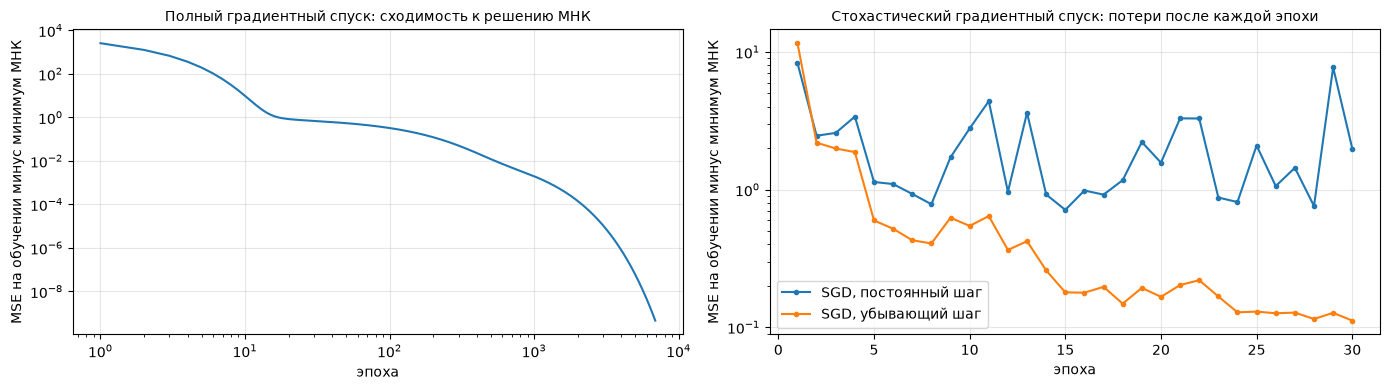

MSE на обучении: МНК 50.09001 | GD 50.09001 | SGD (пост. шаг) 52.07917 | SGD (убыв. шаг) 50.20171


In [25]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
best_loss = my_analytic.loss_history_[0]
ax[0].plot(np.arange(len(my_gd.loss_history_)) + 1, np.array(my_gd.loss_history_) - best_loss + 1e-16)
ax[0].set_xscale("log")
ax[0].set_yscale("log")
ax[0].set_xlabel("эпоха")
ax[0].set_ylabel("MSE на обучении минус минимум МНК")
ax[0].set_title("Полный градиентный спуск: сходимость к решению МНК")

epochs = np.arange(1, len(my_sgd_const.loss_history_))
ax[1].plot(epochs, np.array(my_sgd_const.loss_history_[1:]) - best_loss, marker="o", ms=3, label="SGD, постоянный шаг")
ax[1].plot(epochs, np.array(my_sgd_decay.loss_history_[1:]) - best_loss, marker="o", ms=3, label="SGD, убывающий шаг")
ax[1].set_yscale("log")
ax[1].set_xlabel("эпоха")
ax[1].set_ylabel("MSE на обучении минус минимум МНК")
ax[1].set_title("Стохастический градиентный спуск: потери после каждой эпохи")
ax[1].legend()
plt.tight_layout()
plt.show()

print("MSE на обучении: МНК", f"{best_loss:.5f}", "| GD", f"{my_gd.loss_history_[-1]:.5f}",
      "| SGD (пост. шаг)", f"{my_sgd_const.loss_history_[-1]:.5f}", "| SGD (убыв. шаг)", f"{my_sgd_decay.loss_history_[-1]:.5f}")

### 5.4. Коэффициенты при линейно зависимых признаках

Что будет, если оставить `BaseInterestRate` — точную линейную комбинацию трёх других столбцов? Матрица признаков получит неполный ранг:
существует ненулевой вектор $v$ с $Xv = 0$, и для любого $t$ веса $w + tv$ дают те же предсказания, что и $w$.
Коэффициенты перестают быть единственными, и результат зависит от того, как именно решается задача.

In [26]:
# та же задача, но с добавленным признаком-дубликатом
X_dup = np.column_stack([X_dev, train["BaseInterestRate"].to_numpy(float)[dev_idx]])
dup_names = BASELINE_NAMES + ["BaseInterestRate"]
dup_scaler = ZScoreScaler().fit(X_dup[inner_tr])
Xd_tr, Xd_va = dup_scaler.transform(X_dup[inner_tr]), dup_scaler.transform(X_dup[inner_va])

_, singular_values, Vt = np.linalg.svd(Xd_tr, full_matrices=False)
null_direction = Vt[-1]
print("Ранг матрицы с дубликатом:", np.linalg.matrix_rank(Xd_tr), "из", Xd_tr.shape[1],
      "| наименьшее сингулярное число:", f"{singular_values[-1]:.1e}", "(следующее:", f"{singular_values[-2]:.2f})")
print("Вырожденное направление v (наибольшие компоненты):",
      {dup_names[j]: round(float(null_direction[j]), 3) for j in np.argsort(-np.abs(null_direction))[:4]})

my_dup = MyLinearRegression(method="analytic").fit(Xd_tr, y_tr)
sk_dup = SkLinearRegression().fit(Xd_tr, y_tr)
shifted = my_dup.coef_ + 10.0 * null_direction
print("\nСдвиг весов на 10 * v меняет предсказания не более чем на", f"{np.max(np.abs(Xd_va @ shifted - Xd_va @ my_dup.coef_)):.1e}")

full_rank_pred = my_analytic.predict(X_va)
print("Макс. |разность предсказаний| с моделью без дубликата:  своя реализация",
      f"{np.max(np.abs(my_dup.predict(Xd_va) - full_rank_pred)):.1e}", "| sklearn", f"{np.max(np.abs(sk_dup.predict(Xd_va) - full_rank_pred)):.1e}")
print("Норма вектора весов:  без дубликата", f"{np.linalg.norm(my_analytic.coef_):.3f}", "| с дубликатом, своя реализация",
      f"{np.linalg.norm(my_dup.coef_):.3f}", "| с дубликатом, sklearn", f"{np.linalg.norm(sk_dup.coef_):.3e}")

rows = ["CreditScore", "LoanAmount", "LoanDuration", "BaseInterestRate"]
coef_table = pd.DataFrame({
    "без дубликата": [my_analytic.coef_[BASELINE_NAMES.index(c)] if c in BASELINE_NAMES else np.nan for c in rows],
    "с дубликатом: своя (мин. норма)": [my_dup.coef_[dup_names.index(c)] for c in rows],
    "с дубликатом: sklearn": [sk_dup.coef_[dup_names.index(c)] for c in rows],
}, index=rows)
pd.set_option("display.float_format", lambda v: f"{v:.6g}")
display(coef_table)
pd.set_option("display.float_format", lambda v: f"{v:.4f}")

Ранг матрицы с дубликатом: 43 из 44 | наименьшее сингулярное число: 5.9e-13 (следующее: 5.37)
Вырожденное направление v (наибольшие компоненты): {'BaseInterestRate': -0.708, 'CreditScore': -0.655, 'LoanAmount': 0.214, 'LoanDuration': 0.154}

Сдвиг весов на 10 * v меняет предсказания не более чем на 6.0e-14
Макс. |разность предсказаний| с моделью без дубликата:  своя реализация 2.4e-13 | sklearn 9.6e-14
Норма вектора весов:  без дубликата 11.913 | с дубликатом, своя реализация 11.023 | с дубликатом, sklearn 1.102e+01


,без дубликата,с дубликатом: своя (мин. норма),с дубликатом: sklearn
CreditScore,-6.58305,-3.62271,-3.62271
LoanAmount,1.11844,0.151583,0.151583
LoanDuration,-0.222394,-0.916267,-0.916267
BaseInterestRate,NaN,3.19925,3.19925


Аналитическое решение и GD дают близкие предсказания. SGD за 30 эпох подходит к ним
с небольшой разницей; точного совпадения со sklearn не ожидаю из-за перемешивания строк.
Для зависимых столбцов сравниваю предсказания и ранг матрицы: отдельные коэффициенты
могут сильно отличаться. При другом численном пороге ранга возможны различия между версиями библиотек.

## 6. Подготовка признаков

Сравниваю исходные признаки, логарифмы денежных показателей, кусочно-линейные функции
$h_t(x)=\max(x-t,0)$ и их попарные произведения. Узлы выбираются по обучающим квантилям.
После преобразований прогноз $b+\sum_jw_j\phi_j(x)$ остаётся линейным по итоговым коэффициентам.
Категории кодируются отдельными столбцами; неизвестный уровень получает нули.

In [27]:
dev = train.iloc[dev_idx].reset_index(drop=True)          # рабочая часть (те же строки, что X_dev, y_dev)
hold = train.iloc[hold_idx].reset_index(drop=True)        # отложенная часть
y_hold = y_all[hold_idx]
assert np.array_equal(dev[TARGET].to_numpy(float), y_dev)

LOG_COLS = ["AnnualIncome", "LoanAmount", "MonthlyDebtPayments", "SavingsAccountBalance", "CheckingAccountBalance", "TotalAssets",
            "TotalLiabilities", "MonthlyIncome", "NetWorth", "MonthlyLoanPayment", "TotalDebtToIncomeRatio"]
assert (train[LOG_COLS] > 0).all().all() and (test_raw[LOG_COLS] > 0).all().all(), "логарифмируемые признаки должны быть положительны"


def transformed_numeric(frame):
    """Числовые признаки модели; признаки из LOG_COLS - в логарифмической шкале."""
    columns = []
    for col in MODEL_NUM_COLS:
        values = frame[col].to_numpy(float)
        columns.append(np.log(np.clip(values, 1e-9, None)) if col in LOG_COLS else values)
    return np.column_stack(columns)


class BaselineFeatures:
    def fit(self, frame):
        return self

    def transform(self, frame):
        return baseline_matrix(frame)


class LogFeatures:
    def fit(self, frame):
        return self

    def transform(self, frame):
        return np.hstack([baseline_matrix(frame), np.log(frame[LOG_COLS].to_numpy(float))])


class PiecewiseLinearFeatures:
    """Столбцы [x, max(0, x - k_1), ..., max(0, x - k_m)] для каждого числового признака и one-hot для категориальных.
    Узлы - квантили обучающей части; у бинарных признаков узлов нет."""

    def __init__(self, n_knots=10):
        self.n_knots = n_knots

    def fit(self, frame):
        values = transformed_numeric(frame)
        probabilities = np.linspace(0, 1, self.n_knots + 2)[1:-1]
        self.knots_ = []
        for j in range(values.shape[1]):
            column = values[:, j]
            knots = np.unique(np.quantile(column, probabilities))
            self.knots_.append(knots[(knots > column.min()) & (knots < column.max())])
        return self

    def transform(self, frame):
        values = transformed_numeric(frame)
        blocks = []
        for j, knots in enumerate(self.knots_):
            blocks.append(values[:, [j]])
            if len(knots):
                blocks.append(np.maximum(values[:, [j]] - knots[None, :], 0.0))
        blocks.append(one_hot(frame))
        return np.hstack(blocks)

    def plain(self, frame):
        """Те же признаки без изломов: по одному столбцу на признак."""
        return np.hstack([transformed_numeric(frame), one_hot(frame)])


class PiecewisePlusProducts(PiecewiseLinearFeatures):
    """Кусочно-линейный базис и попарные произведения десяти основных признаков (после z-score)."""

    MAIN = ["MonthlyIncome", "CreditScore", "TotalDebtToIncomeRatio", "InterestRate", "NetWorth", "DebtToIncomeRatio",
            "LoanAmount", "BankruptcyHistory", "LengthOfCreditHistory", "CreditCardUtilizationRate"]

    def fit(self, frame):
        super().fit(frame)
        self.main_idx_ = [MODEL_NUM_COLS.index(col) for col in self.MAIN]
        self.main_scaler_ = ZScoreScaler().fit(transformed_numeric(frame)[:, self.main_idx_])
        return self

    def transform(self, frame):
        z = self.main_scaler_.transform(transformed_numeric(frame)[:, self.main_idx_])
        products = [z[:, a] * z[:, b] for a, b in itertools.combinations(range(z.shape[1]), 2)]
        return np.hstack([super().transform(frame), np.column_stack(products)])


class FeatureModel:
    """Признаки -> z-score -> собственная линейная регрессия (аналитическое решение, при alpha > 0 с L2-штрафом)."""

    def __init__(self, make_features, alpha=0.0):
        self.make_features = make_features
        self.alpha = alpha

    def fit(self, frame, y):
        self.features_ = self.make_features().fit(frame)
        params = dict(method="analytic", penalty="l2", alpha=self.alpha) if self.alpha > 0 else dict(method="analytic")
        self.model_ = ScaledLinearModel(**params).fit(self.features_.transform(frame), y)
        return self

    def predict(self, frame):
        return self.model_.predict(self.features_.transform(frame))


print("Столбцов в матрице признаков:  E0 -", BaselineFeatures().fit(dev).transform(dev).shape[1],
      "| E1 -", LogFeatures().fit(dev).transform(dev).shape[1],
      "| E2 -", PiecewiseLinearFeatures(10).fit(dev).transform(dev).shape[1],
      "| E3 -", PiecewisePlusProducts(10).fit(dev).transform(dev).shape[1])

Столбцов в матрице признаков:  E0 - 43 | E1 - 54 | E2 - 257 | E3 - 302


## 7. Кросс-валидация k-fold

**k-fold.** Индексы $0..n-1$ (после перемешивания с заданным зерном) режутся на $k$ блоков; если $n$ не делится на $k$, первые $n \bmod k$ блоков
получают на один объект больше. Каждый блок по очереди служит валидационным, остальные — обучающими.
На каждом разбиении создаётся **новая** модель, и все её преобразования (здесь z-score) обучаются только на обучающих блоках.

**Leave-one-out (LOO).** Частный случай $k = n$: каждый объект по очереди остаётся единственным валидационным.
Метрики LOO считаются по всему вектору предсказаний «вне обучения»; усреднять $R^2$ по одноэлементным выборкам нельзя — он там не определён.

In [28]:
def kfold_indices(n, k=5, shuffle=True, random_state=None):
    """Список из k пар (train_idx, val_idx)."""
    if not 2 <= k <= n:
        raise ValueError("нужно 2 <= k <= n")
    order = np.random.default_rng(random_state).permutation(n) if shuffle else np.arange(n)
    sizes = np.full(k, n // k)
    sizes[: n % k] += 1
    splits, start = [], 0
    for size in sizes:
        val_idx = order[start:start + size]
        train_idx = np.concatenate([order[:start], order[start + size:]])
        splits.append((train_idx, val_idx))
        start += size
    return splits


def loo_indices(n):
    """Генератор n пар (train_idx, val_idx): каждый объект по очереди - единственный валидационный."""
    everything = np.arange(n)
    for i in range(n):
        yield np.delete(everything, i), np.array([i])


def take_rows(X, idx):
    return X.iloc[idx] if hasattr(X, "iloc") else X[idx]


def oof_predictions(make_model, X, y, splits):
    """Предсказания «вне обучения»: для каждого разбиения новая модель обучается на train-части и предсказывает val-часть."""
    y = np.asarray(y, dtype=float)
    oof = np.full(len(y), np.nan)
    for train_idx, val_idx in splits:
        model = make_model()
        model.fit(take_rows(X, train_idx), y[train_idx])
        oof[val_idx] = model.predict(take_rows(X, val_idx))
    return oof


def cross_validate(make_model, X, y, splits):
    """Таблица метрик по разбиениям и вектор предсказаний вне обучения."""
    y = np.asarray(y, dtype=float)
    oof = oof_predictions(make_model, X, y, splits)
    table = pd.DataFrame([all_metrics(y[val_idx], oof[val_idx]) for _, val_idx in splits])
    table.index = [f"fold {i + 1}" for i in range(len(splits))]
    return table, oof


class ScaledLinearModel:
    """z-score (собственный) + собственная линейная регрессия; нормализация обучается внутри fit."""

    def __init__(self, **regression_params):
        self.regression_params = regression_params

    def fit(self, X, y):
        self.scaler = ZScoreScaler().fit(X)
        self.model = MyLinearRegression(**self.regression_params).fit(self.scaler.transform(X), y)
        return self

    def predict(self, X):
        return self.model.predict(self.scaler.transform(X))

In [29]:
# --- проверка разбиений: n не делится на k
n_check, k_check = 103, 5
splits_check = kfold_indices(n_check, k_check, shuffle=True, random_state=SEED)
val_sizes = [len(v) for _, v in splits_check]
all_val = np.concatenate([v for _, v in splits_check])
print("Размеры валидационных блоков при n = 103, k = 5:", val_sizes)
assert sorted(val_sizes, reverse=True) == [21, 21, 21, 20, 20]
assert all(len(np.intersect1d(t, v)) == 0 for t, v in splits_check), "train и val пересекаются"
assert all(len(t) + len(v) == n_check for t, v in splits_check)
assert np.array_equal(np.sort(all_val), np.arange(n_check)), "каждый объект должен попасть в валидацию ровно один раз"

# --- воспроизводимость
again = kfold_indices(n_check, k_check, shuffle=True, random_state=SEED)
other = kfold_indices(n_check, k_check, shuffle=True, random_state=SEED + 1)
assert all(np.array_equal(a[1], b[1]) for a, b in zip(splits_check, again))
assert not all(np.array_equal(a[1], b[1]) for a, b in zip(splits_check, other))

# --- без перемешивания разбиения совпадают со sklearn.KFold
plain = kfold_indices(n_check, k_check, shuffle=False)
sk_plain = list(KFold(n_splits=k_check, shuffle=False).split(np.zeros(n_check)))
assert all(np.array_equal(a[0], b[0]) and np.array_equal(a[1], b[1]) for a, b in zip(plain, sk_plain))

# --- LOO
loo_check = list(loo_indices(7))
assert len(loo_check) == 7 and all(len(v) == 1 and len(t) == 6 and v[0] not in t for t, v in loo_check)
assert sorted(int(v[0]) for _, v in loo_check) == list(range(7))
print("Проверки разбиений k-fold и LOO пройдены.")

Размеры валидационных блоков при n = 103, k = 5: [21, 21, 21, 20, 20]


Проверки разбиений k-fold и LOO пройдены.


In [30]:
# --- 5-fold на рабочей части, базовая модель (z-score + аналитическое решение)
cv_splits = kfold_indices(len(y_dev), k=5, shuffle=True, random_state=SEED)
base_folds, base_oof = cross_validate(lambda: ScaledLinearModel(), X_dev, y_dev, cv_splits)
summary = pd.concat([base_folds, base_folds.agg(["mean", "std"])])
display(summary)

# --- та же проверка через sklearn на тех же разбиениях и с той же обработкой
sk_oof = cross_val_predict(make_pipeline(SkStandardScaler(), SkLinearRegression()), X_dev, y_dev, cv=cv_splits)
sk_fold_mse = [mean_squared_error(y_dev[v], sk_oof[v]) for _, v in cv_splits]
print("Макс. |разность| предсказаний вне обучения со sklearn:", f"{np.max(np.abs(base_oof - sk_oof)):.2e}")
print("Макс. |разность| MSE по разбиениям:", f"{np.max(np.abs(base_folds['MSE'].values - np.array(sk_fold_mse))):.2e}")

,MSE,MAE,R2,MAPE
fold 1,51.6736,5.8359,0.8218,0.1360
fold 2,50.6300,5.8243,0.8294,0.1370
fold 3,51.4059,5.6315,0.8291,0.1357
fold 4,50.0126,5.6360,0.8336,0.1333
fold 5,50.2066,5.6623,0.8327,0.1289
mean,50.7858,5.7180,0.8293,0.1342
std,0.7298,0.1031,0.0047,0.0032


Макс. |разность| предсказаний вне обучения со sklearn: 2.42e-13
Макс. |разность| MSE по разбиениям: 1.42e-14


## 8. Регуляризация L1, L2, L1+L2 и Lp

Все штрафы добавляются к одной и той же функции потерь $L(w, b) = \frac1n \|y - Xw - b\|^2 + R(w)$; свободный член не штрафуется.
Штраф зависит от масштаба признаков, поэтому регуляризация применяется к признакам после z-score.

| штраф | $R(w)$ | как оптимизируется |
|---|---|---|
| L2 | $\alpha \sum_j w_j^2$ | аналитически: $(X_c^\top X_c / n + \alpha I)\, w = X_c^\top y_c / n$; в GD и SGD — слагаемое $2\alpha w$ в градиенте |
| L1 | $\alpha \sum_j \lvert w_j \rvert$ | проксимальный градиентный спуск (см. ниже) |
| L1+L2 | $\alpha \bigl(\rho \sum_j \lvert w_j \rvert + (1 - \rho) \sum_j w_j^2\bigr)$ | гладкая L2-часть — градиентом, L1-часть — проксимальным шагом |
| Lp | $\alpha \sum_j \lvert w_j \rvert^p$, $p \ge 1$ задаёт пользователь | при $p > 1$ — градиентом $\alpha p \lvert w_j \rvert^{p-1} \operatorname{sign}(w_j)$; при $p = 1$ — как L1 |

**Недифференцируемость L1 в нуле.** У $|w_j|$ в нуле нет производной, поэтому обычный градиентный шаг не годится (и никогда не даёт точных нулей).
Используется проксимальный шаг: сначала обычный шаг по гладкой части потерь, $v = w - \eta \nabla_{\text{гладк}}$, затем мягкое пороговое отсечение
$w_j = \operatorname{sign}(v_j) \max(\lvert v_j \rvert - \eta\alpha, 0)$. Это точное решение одномерной задачи
$\min_w \frac{1}{2\eta}(w - v_j)^2 + \alpha \lvert w \rvert$. Вес остаётся ровно нулём, пока производная гладкой части по нему не превышает $\alpha$
по модулю — это и есть условие оптимальности через субградиент.

**Lp: что именно реализовано.** Штраф — сумма $p$-х степеней модулей весов, а не сама норма $\|w\|_p$ (без корня степени $p$): при $p = 2$ он совпадает
с L2-штрафом, при $p = 1$ — с L1. Поддерживается $p \ge 1$: при $p < 1$ задача невыпуклая, и градиентный спуск не гарантирует глобального минимума,
поэтому такие значения отвергаются с ошибкой. Диапазон выбран мной — в методичке он не задан. При $1 < p < 2$ производная штрафа непрерывна,
но около нуля меняется очень быстро, поэтому малые веса не обнуляются точно, а колеблются около нуля с малой амплитудой.

**Соответствие со `sklearn`** (в `sklearn` другие масштабы ошибки и штрафа, одинаковое число `alpha` означает разные задачи):

| наша запись | `sklearn` | что минимизирует `sklearn` |
|---|---|---|
| L2, $\alpha$ | `Ridge(alpha = α·n)` | $\|y - Xw\|^2 + \text{alpha}\,\|w\|_2^2$ |
| L1, $\alpha$ | `Lasso(alpha = α/2)` | $\frac{1}{2n}\|y - Xw\|^2 + \text{alpha}\,\|w\|_1$ |
| L1+L2, $(\alpha, \rho)$ | `ElasticNet(alpha = α(1 − ρ/2), l1_ratio = ρ/(2 − ρ))` | $\frac{1}{2n}\|y - Xw\|^2 + \text{alpha}\cdot\text{l1\_ratio}\,\|w\|_1 + \frac12 \text{alpha}(1 - \text{l1\_ratio})\,\|w\|_2^2$ |

### 7.1. Проверка реализаций

In [31]:
n_tr = len(y_tr)
lam_max = eig.max()                     # наибольшее собственное значение X^T X / n (посчитано в разделе 5)


def objective(model, X, y, penalty, alpha, l1_ratio=0.5, p=2.0):
    """Значение нашей функции потерь для коэффициентов любой модели (своей или из sklearn)."""
    w = np.ravel(model.coef_)
    b = float(np.ravel(model.intercept_)[0])
    data = float(np.mean((y - X @ w - b) ** 2))
    if penalty == "l2":
        return data + alpha * np.sum(w ** 2)
    if penalty == "l1":
        return data + alpha * np.sum(np.abs(w))
    if penalty == "elasticnet":
        return data + alpha * (l1_ratio * np.sum(np.abs(w)) + (1 - l1_ratio) * np.sum(w ** 2))
    return data + alpha * np.sum(np.abs(w) ** p)


def smooth_gradient(model, X, y):
    """Градиент гладкой части потерь 1/n * ||y - Xw - b||^2 по весам."""
    return 2.0 / len(y) * X.T @ (X @ np.ravel(model.coef_) + float(model.intercept_) - y)


ALPHA = 0.5
RHO = 0.5
gd_common = dict(method="gd", n_epochs=200000, tol=1e-15)

# --- L2: аналитика, градиентный спуск, SGD и sklearn.Ridge
my_l2 = MyLinearRegression(method="analytic", penalty="l2", alpha=ALPHA).fit(X_tr, y_tr)
my_l2_gd = MyLinearRegression(penalty="l2", alpha=ALPHA, lr=0.5 / (lam_max + ALPHA), **gd_common).fit(X_tr, y_tr)
my_l2_sgd = MyLinearRegression(method="sgd", penalty="l2", alpha=ALPHA, lr=1e-3, lr_decay=1e-4, n_epochs=15, tol=0.0,
                               random_state=SEED).fit(X_tr, y_tr)
sk_ridge = Ridge(alpha=ALPHA * n_tr).fit(X_tr, y_tr)

# --- L1: проксимальный градиентный спуск и sklearn.Lasso
my_l1 = MyLinearRegression(penalty="l1", alpha=ALPHA, lr=0.5 / lam_max, **gd_common).fit(X_tr, y_tr)
sk_lasso = Lasso(alpha=ALPHA / 2, max_iter=200000, tol=1e-13).fit(X_tr, y_tr)

# --- L1+L2 и sklearn.ElasticNet
my_en = MyLinearRegression(penalty="elasticnet", alpha=ALPHA, l1_ratio=RHO, lr=0.5 / (lam_max + ALPHA * (1 - RHO)), **gd_common).fit(X_tr, y_tr)
sk_en = ElasticNet(alpha=ALPHA * (1 - RHO / 2), l1_ratio=RHO / (2 - RHO), max_iter=200000, tol=1e-13).fit(X_tr, y_tr)

checks = [
    ("L2: своя аналитика / Ridge", my_l2, sk_ridge, "l2"),
    ("L2: свой GD / Ridge", my_l2_gd, sk_ridge, "l2"),
    ("L2: свой SGD (15 эпох) / Ridge", my_l2_sgd, sk_ridge, "l2"),
    ("L1: свой проксимальный GD / Lasso", my_l1, sk_lasso, "l1"),
    ("L1+L2: свой проксимальный GD / ElasticNet", my_en, sk_en, "elasticnet"),
]
rows = []
for name, own, ref, penalty in checks:
    rows.append({
        "сравнение": name,
        "потери (своя)": objective(own, X_tr, y_tr, penalty, ALPHA, RHO),
        "потери (sklearn)": objective(ref, X_tr, y_tr, penalty, ALPHA, RHO),
        "макс. |разность коэф.|": np.max(np.abs(own.coef_ - ref.coef_)),
        "макс. |разность предсказаний|": np.max(np.abs(own.predict(X_va) - ref.predict(X_va))),
        "нулевых весов (своя / sklearn)": f"{int(np.sum(own.coef_ == 0))} / {int(np.sum(ref.coef_ == 0))}",
        "эпох": own.n_iter_,
    })
pd.set_option("display.float_format", lambda v: f"{v:.8g}")
display(pd.DataFrame(rows).set_index("сравнение"))
pd.set_option("display.float_format", lambda v: f"{v:.4f}")

# --- условия оптимальности для L1: при w_j != 0 производная гладкой части равна -alpha * sign(w_j), при w_j = 0 не превышает alpha
g = smooth_gradient(my_l1, X_tr, y_tr)
active = my_l1.coef_ != 0
print("L1, условия оптимальности: макс. отклонение на ненулевых весах",
      f"{np.max(np.abs(g[active] + ALPHA * np.sign(my_l1.coef_[active]))):.1e};",
      "макс. |производная| на нулевых весах", f"{np.max(np.abs(g[~active])):.4f}", f"(должна быть не больше alpha = {ALPHA})")
print("Признаки, обнулённые L1-штрафом:", [BASELINE_NAMES[j] for j in np.where(~active)[0]])

,потери (своя),потери (sklearn),макс. |разность коэф.|,макс. |разность предсказаний|,нулевых весов (своя / sklearn),эпох
сравнение,,,,,,
L2: своя аналитика / Ridge,87.156389,87.156389,4.4408921e-15,2.8421709e-14,0 / 0,1
L2: свой GD / Ridge,87.156389,87.156389,1.1451546e-06,4.2697254e-06,0 / 0,90
L2: свой SGD (15 эпох) / Ridge,87.224558,87.156389,0.065158548,1.4014444,0 / 0,15
L1: свой проксимальный GD / Lasso,64.695231,64.695231,0.00013891772,0.0004080107,26 / 26,6663
L1+L2: свой проксимальный GD / ElasticNet,77.614263,77.614263,1.7028262e-06,6.2315957e-06,21 / 21,172


L1, условия оптимальности: макс. отклонение на ненулевых весах 1.3e-06; макс. |производная| на нулевых весах 0.4798 (должна быть не больше alpha = 0.5)
Признаки, обнулённые L1-штрафом: ['Age', 'AnnualIncome', 'LoanDuration', 'NumberOfDependents', 'NumberOfOpenCreditLines', 'NumberOfCreditInquiries', 'PaymentHistory', 'SavingsAccountBalance', 'CheckingAccountBalance', 'UtilityBillsPaymentHistory', 'JobTenure', 'Experience', 'MonthlyLoanPayment', 'MaritalStatus=Married', 'MaritalStatus=Single', 'MaritalStatus=Widowed', 'HomeOwnershipStatus=Other', 'HomeOwnershipStatus=Own', 'LoanPurpose=Debt Consolidation', 'LoanPurpose=Education', 'LoanPurpose=Home', 'LoanPurpose=Other', 'EducationLevel=Bachelor', 'EducationLevel=Doctorate', 'EducationLevel=High School', 'EducationLevel=Master']


In [32]:
# --- Lp-штраф при разных p
lp_rows = []
lp_models = {}
for p in [1.0, 1.5, 2.0, 3.0]:
    lr = 0.25 / (lam_max + 10 * ALPHA)                       # с запасом: при p = 3 кривизна штрафа растёт вместе с |w|
    model = MyLinearRegression(method="gd", penalty="lp", alpha=ALPHA, p=p, lr=lr, n_epochs=100000, tol=1e-15).fit(X_tr, y_tr)
    lp_models[p] = model
    w = model.coef_
    full_grad = smooth_gradient(model, X_tr, y_tr) + (ALPHA * p * np.abs(w) ** (p - 1) * np.sign(w) if p > 1 else 0.0)
    big = np.abs(w) > 1e-2                                   # условие стационарности проверяется на весах, далёких от нуля
    lp_rows.append({
        "p": p,
        "сумма |w|": np.sum(np.abs(w)), "сумма w^2": np.sum(w ** 2), "макс. |w|": np.max(np.abs(w)),
        "весов с |w| < 0.001": int(np.sum(np.abs(w) < 1e-3)),
        "MSE (обучение)": mse(y_tr, model.predict(X_tr)), "MSE (проверка)": mse(y_va, model.predict(X_va)),
        "макс. |градиент| на весах с |w| > 0.01": np.max(np.abs(full_grad[big])) if p > 1 else np.nan,
        "эпох": model.n_iter_, "остановка по tol": model.converged_,
    })
display(pd.DataFrame(lp_rows).set_index("p"))

print("p = 2: макс. |разность коэффициентов| с аналитическим L2-решением при том же alpha:",
      f"{np.max(np.abs(lp_models[2.0].coef_ - my_l2.coef_)):.1e}")
print("p = 1: макс. |разность коэффициентов| с L1-решением при том же alpha:",
      f"{np.max(np.abs(lp_models[1.0].coef_ - my_l1.coef_)):.1e}", "| со sklearn.Lasso:",
      f"{np.max(np.abs(lp_models[1.0].coef_ - sk_lasso.coef_)):.1e}")
for bad_p in (0.5, float("inf")):
    try:
        MyLinearRegression(method="gd", penalty="lp", alpha=ALPHA, p=bad_p).fit(X_tr, y_tr)
    except ValueError as error:
        print(f"p = {bad_p}: ValueError -", error)
try:
    MyLinearRegression(method="analytic", penalty="l1", alpha=ALPHA).fit(X_tr, y_tr)
except ValueError as error:
    print("L1 + method='analytic': ValueError -", error)

,сумма |w|,сумма w^2,макс. |w|,весов с |w| < 0.001,MSE (обучение),MSE (проверка),макс. |градиент| на весах с |w| > 0.01,эпох,остановка по tol
p,,,,,,,,,
1.0000,26.9953,119.5238,7.6460,26,51.1976,51.0374,NaN,27514,True
1.5000,26.3329,74.4316,4.7827,4,52.8575,52.5394,0.0000,1638,True
2.0000,25.3228,59.0194,3.7775,1,57.6467,57.5721,0.0000,359,True
3.0000,22.9942,34.5686,2.5151,0,83.0708,85.4435,0.0000,950,True


p = 2: макс. |разность коэффициентов| с аналитическим L2-решением при том же alpha: 3.0e-06
p = 1: макс. |разность коэффициентов| с L1-решением при том же alpha: 2.5e-04 | со sklearn.Lasso: 3.9e-04
p = 0.5: ValueError - для Lp-штрафа поддерживается только конечное p >= 1 (при p < 1 задача невыпуклая)
p = inf: ValueError - для Lp-штрафа поддерживается только конечное p >= 1 (при p < 1 задача невыпуклая)
L1 + method='analytic': ValueError - аналитическое решение есть только без штрафа и с L2-штрафом; для L1, L1+L2 и Lp используйте method='gd' или 'sgd'


### Влияние силы регуляризации на качество и коэффициенты

Сила штрафа подбирается только по данным рабочей части: модель обучается на её обучающей доле, качество считается на её проверочной доле.
Отложенная часть и `test.csv` здесь не используются. В значение MSE штраф не входит.

,L2: MSE (проверка),L2: норма весов,L1: MSE (проверка),L1: ненулевых весов,L1: сумма |w|
alpha,,,,,
0.0000,49.7549,11.9127,49.7549,43,34.6782
0.0010,49.7377,11.6542,49.7518,43,34.3108
0.0100,49.7292,10.5212,49.7385,39,32.8848
0.0300,49.8740,9.7682,49.7473,36,32.1362
0.1000,50.5054,9.1023,49.8017,30,30.5354
0.3000,53.4660,8.2702,50.2700,19,28.5256
1.0000,69.7860,6.6217,53.7197,13,24.0438
3.0000,116.8070,4.4246,65.8312,7,18.1022


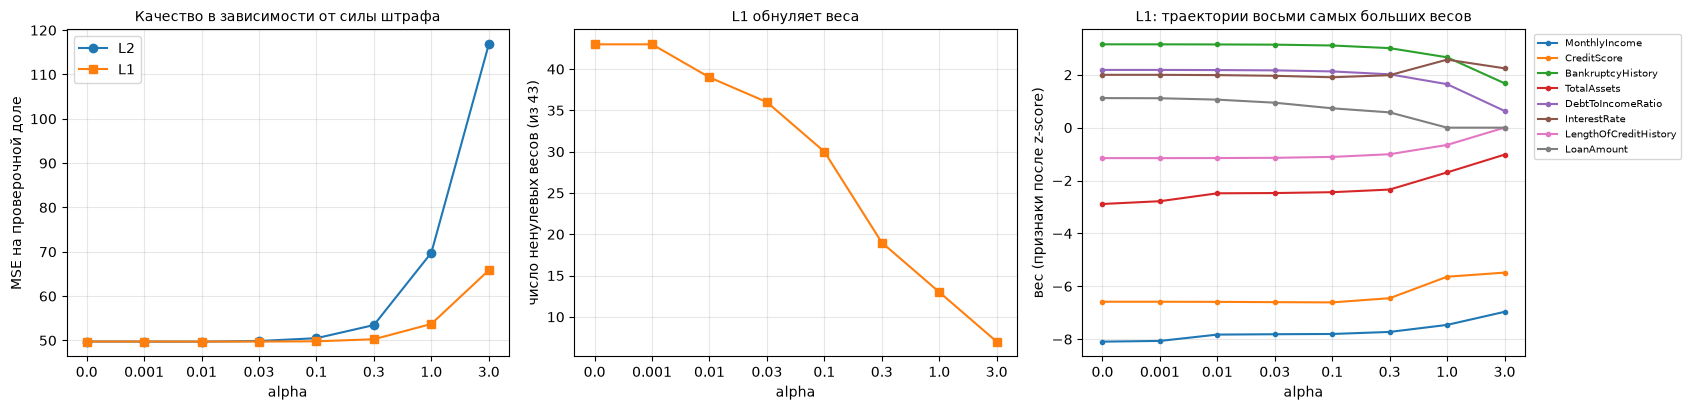

Лучшее alpha по проверочной доле: L2 - 0.01 | L1 - 0.01
При alpha = 1 L1 оставляет признаки: ['CreditScore', 'CreditCardUtilizationRate', 'DebtToIncomeRatio', 'BankruptcyHistory', 'PreviousLoanDefaults', 'LengthOfCreditHistory', 'TotalAssets', 'MonthlyIncome', 'NetWorth', 'InterestRate', 'TotalDebtToIncomeRatio', 'EmploymentStatus=Self-Employed', 'EmploymentStatus=Unemployed']


In [33]:
alphas = [0.0, 0.001, 0.01, 0.03, 0.1, 0.3, 1.0, 3.0]
path = []
l1_coefs = []
for a in alphas:
    if a == 0:
        l2_model = MyLinearRegression(method="analytic").fit(X_tr, y_tr)
        l1_model = l2_model
    else:
        l2_model = MyLinearRegression(method="analytic", penalty="l2", alpha=a).fit(X_tr, y_tr)
        l1_model = MyLinearRegression(method="gd", penalty="l1", alpha=a, lr=0.5 / lam_max, n_epochs=100000, tol=1e-14).fit(X_tr, y_tr)
    l1_coefs.append(l1_model.coef_.copy())
    path.append({"alpha": a,
                 "L2: MSE (проверка)": mse(y_va, l2_model.predict(X_va)), "L2: норма весов": np.linalg.norm(l2_model.coef_),
                 "L1: MSE (проверка)": mse(y_va, l1_model.predict(X_va)), "L1: ненулевых весов": int(np.sum(l1_model.coef_ != 0)),
                 "L1: сумма |w|": np.sum(np.abs(l1_model.coef_))})
path = pd.DataFrame(path).set_index("alpha")
display(path)

x_pos = np.arange(len(alphas))
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
ax[0].plot(x_pos, path["L2: MSE (проверка)"], marker="o", label="L2")
ax[0].plot(x_pos, path["L1: MSE (проверка)"], marker="s", label="L1")
ax[0].set_ylabel("MSE на проверочной доле")
ax[0].set_title("Качество в зависимости от силы штрафа")
ax[0].legend()
ax[1].plot(x_pos, path["L1: ненулевых весов"], marker="s", color="tab:orange")
ax[1].set_ylabel("число ненулевых весов (из %d)" % X_tr.shape[1])
ax[1].set_title("L1 обнуляет веса")
l1_coefs = np.array(l1_coefs)
strongest = np.argsort(-np.abs(l1_coefs[0]))[:8]
for j in strongest:
    ax[2].plot(x_pos, l1_coefs[:, j], marker=".", label=BASELINE_NAMES[j])
ax[2].set_ylabel("вес (признаки после z-score)")
ax[2].set_title("L1: траектории восьми самых больших весов")
ax[2].legend(fontsize=7, loc="upper left", bbox_to_anchor=(1.01, 1.0))
for a in ax:
    a.set_xticks(x_pos)
    a.set_xticklabels([str(v) for v in alphas])
    a.set_xlabel("alpha")
plt.tight_layout()
plt.show()

best_l2, best_l1 = path["L2: MSE (проверка)"].idxmin(), path["L1: MSE (проверка)"].idxmin()
print("Лучшее alpha по проверочной доле: L2 -", best_l2, "| L1 -", best_l1)
print("При alpha = 1 L1 оставляет признаки:", [BASELINE_NAMES[j] for j in np.where(l1_coefs[alphas.index(1.0)] != 0)[0]])

L1 и L1+L2 проверены через Lasso и ElasticNet, L2 — через Ridge.
Для Lp проверены несколько p и связи с L1 при p=1 и L2 при p=2.
На небольшом базовом наборе слабые штрафы почти не меняют качество; сильные ухудшают его.
В расширенном наборе много связанных столбцов, поэтому далее использую L2.

## 9. Экспериментальная модель и выбор настроек

### 9.1. Модель со скрытыми группами

Проверяю представление $y\approx f(x)-r\,g(x)+\varepsilon$, где $r\in\{0,1\}$ — метка группы.
Начальную метку задаёт условие $y<49$. Затем три раза обучаю регрессию на
$[\Phi(x),r,r\Psi(x)]$ и выбираю для обучающей строки группу с меньшей ошибкой.

Отдельная линейная регрессия предсказывает метку группы по входным признакам.
Её шесть раз переобучаю на 30% строк около границы. Из полученного скора строю
кусочно-линейные функции и взаимодействия с исходными признаками.
Окончательный прогноз даёт L2-регрессия на этой расширенной матрице.

Метки и все модели пересчитываются внутри train-части каждого фолда.
Для новых строк используются только их признаки. Это многоэтапный эксперимент
со скрытыми группами; в основной версии используется одна итоговая регрессия.

In [34]:
def best_split_threshold(score, label):
    """Порог t, при котором правило «label = 1, если score > t» ошибается на наименьшем числе объектов."""
    order = np.argsort(score, kind="stable")
    sorted_label = label[order]
    ones_left = np.cumsum(sorted_label)
    zeros_left = np.arange(1, len(sorted_label) + 1) - ones_left
    correct = zeros_left + (sorted_label.sum() - ones_left)           # нули слева от порога и единицы справа
    return float(score[order][int(np.argmax(correct))])


class RegimeRegressor:
    """Линейная регрессия по кусочно-линейным признакам и признакам скрытого режима. Все обучаемые части - МНК."""

    def __init__(self, n_knots=10, alpha=1e-3, use_regime=True, start_threshold=49.0, n_label_iter=3, n_local=6, band=0.3,
                 n_score_knots=12, score_clip=6.0, alpha_score=1e-4, date_age_features=True):
        self.n_knots = n_knots
        self.alpha = alpha
        self.use_regime = use_regime
        self.start_threshold = start_threshold
        self.n_label_iter = n_label_iter
        self.n_local = n_local
        self.band = band
        self.n_score_knots = n_score_knots
        self.score_clip = score_clip
        self.alpha_score = alpha_score
        self.date_age_features = date_age_features

    @staticmethod
    def _least_squares(X, y, alpha):
        return ScaledLinearModel(method="analytic", penalty="l2", alpha=alpha).fit(X, y)

    # ---------------------------------------------------------------- признаки скора режима
    def score_feature_names(self):
        names = MODEL_NUM_COLS + ONE_HOT_NAMES
        if self.date_age_features:
            names = names + ["max(0, Age - 30)", "max(0, Age - 40)", "max(0, Age - 50)"] + [f"месяц = {m}" for m in range(2, 13)]
        return names

    def _score_matrix(self, frame):
        blocks = [frame[MODEL_NUM_COLS].to_numpy(float), one_hot(frame)]
        if self.date_age_features:
            age = frame["Age"].to_numpy(float)
            month = pd.to_datetime(frame[DATE_COL]).dt.month.to_numpy()
            blocks.append(np.column_stack([np.maximum(age - k, 0.0) for k in (30, 40, 50)]))
            blocks.append(np.column_stack([(month == m).astype(float) for m in range(2, 13)]))
        return np.hstack(blocks)

    # ---------------------------------------------------------------- шаг 1: метки режима
    def _relabel(self, Phi, Psi, y, labels):
        n = len(y)
        column = labels[:, None]
        model = self._least_squares(np.hstack([Phi, column, Psi * column]), y, self.alpha)
        pred_low = model.predict(np.hstack([Phi, np.ones((n, 1)), Psi]))                    # как если бы объект был в низком режиме
        pred_high = model.predict(np.hstack([Phi, np.zeros((n, 1)), np.zeros_like(Psi)]))   # как если бы в высоком
        new_labels = (np.abs(y - pred_low) < np.abs(y - pred_high)).astype(float)
        return new_labels, pred_low, pred_high

    # ---------------------------------------------------------------- шаг 3: признаки итоговой регрессии
    def _final_matrix(self, Phi, Psi, score):
        s = np.clip(score, -self.score_clip, self.score_clip)
        link = np.column_stack([s] + [np.maximum(s - k, 0.0) for k in self.score_knots_])
        ramp = (np.clip(s, self.ramp_low_, self.ramp_high_) - self.ramp_low_) / (self.ramp_high_ - self.ramp_low_)
        return np.hstack([Phi, link, Psi * ramp[:, None]])

    def fit(self, frame, y):
        y = np.asarray(y, dtype=float)
        self.basis_ = PiecewiseLinearFeatures(self.n_knots).fit(frame)
        Phi = self.basis_.transform(frame)
        if not self.use_regime:
            self.final_ = self._least_squares(Phi, y, self.alpha)
            return self
        self.psi_scaler_ = ZScoreScaler().fit(self.basis_.plain(frame))
        Psi = self.psi_scaler_.transform(self.basis_.plain(frame))

        # шаг 1: метки режима по обучающим объектам
        labels = (y < self.start_threshold).astype(float)
        pred_low = pred_high = None
        for _ in range(self.n_label_iter):
            labels, pred_low, pred_high = self._relabel(Phi, Psi, y, labels)

        # шаг 2: скор режима - регрессия метки на признаки, затем переобучение около границы
        S = self._score_matrix(frame)
        target = 2.0 * labels - 1.0
        model = self._least_squares(S, target, self.alpha_score)
        raw = model.predict(S)
        shift = best_split_threshold(raw, labels)
        for _ in range(self.n_local):
            distance = np.abs(raw - shift)
            near = distance <= np.quantile(distance, self.band)
            model = self._least_squares(S[near], target[near], self.alpha_score)
            raw = model.predict(S)
            shift = best_split_threshold(raw, labels)
        self.score_model_ = model
        self.score_shift_ = shift
        self.score_scale_ = float(np.median(np.abs(raw - shift)))
        score = (raw - shift) / self.score_scale_

        # шаг 3: итоговая регрессия
        s = np.clip(score, -self.score_clip, self.score_clip)
        knots = np.unique(np.quantile(s, np.linspace(0, 1, self.n_score_knots + 2)[1:-1]))
        self.score_knots_ = knots[(knots > s.min()) & (knots < s.max())]
        self.ramp_low_, self.ramp_high_ = np.quantile(s, [0.3, 0.7])
        self.final_ = self._least_squares(self._final_matrix(Phi, Psi, score), y, self.alpha)

        self.labels_, self.pred_low_, self.pred_high_, self.train_score_ = labels, pred_low, pred_high, score
        return self

    def regime_score(self, frame):
        """Скор режима: 0 - граница, положительные значения - низкорисковый режим. Зависит только от признаков."""
        return (self.score_model_.predict(self._score_matrix(frame)) - self.score_shift_) / self.score_scale_

    def predict(self, frame):
        Phi = self.basis_.transform(frame)
        if not self.use_regime:
            return self.final_.predict(Phi)
        Psi = self.psi_scaler_.transform(self.basis_.plain(frame))
        return self.final_.predict(self._final_matrix(Phi, Psi, self.regime_score(frame)))

### 9.2. Сравнение вариантов

,MSE,ст. откл. MSE по разбиениям,MAE,R2,MAPE,"время, c"
вариант,,,,,,
E0. базовый набор,50.7858,0.7298,5.7180,0.8293,0.1342,0.1000
E1. + логарифмы,37.5896,1.0688,4.8346,0.8737,0.1110,0.1000
"E2. кусочно-линейный базис (10 узлов), L2 alpha=0.001",26.2210,1.1959,3.8715,0.9119,0.0909,0.4000
"E3. E2 + попарные произведения, L2 alpha=0.001",25.2778,1.2819,3.7893,0.9150,0.0881,0.6000
"E4. E2 + признаки скрытого режима, L2 alpha=0.001",20.0282,1.3153,3.1932,0.9327,0.0740,2.4000


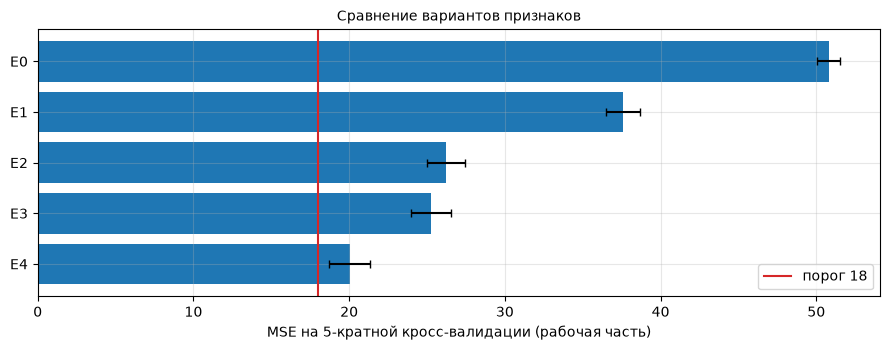

In [35]:
experiments = {
    "E0. базовый набор": lambda: FeatureModel(BaselineFeatures),
    "E1. + логарифмы": lambda: FeatureModel(LogFeatures),
    "E2. кусочно-линейный базис (10 узлов), L2 alpha=0.001": lambda: RegimeRegressor(use_regime=False),
    "E3. E2 + попарные произведения, L2 alpha=0.001": lambda: FeatureModel(lambda: PiecewisePlusProducts(10), alpha=1e-3),
    "E4. E2 + признаки скрытого режима, L2 alpha=0.001": lambda: RegimeRegressor(),
}
results, oof_by_experiment = [], {}
for name, make_model in experiments.items():
    t0 = time.time()
    folds, oof = cross_validate(make_model, dev, y_dev, cv_splits)
    oof_by_experiment[name] = oof
    results.append({"вариант": name, "MSE": folds["MSE"].mean(), "ст. откл. MSE по разбиениям": folds["MSE"].std(),
                    "MAE": folds["MAE"].mean(), "R2": folds["R2"].mean(), "MAPE": folds["MAPE"].mean(),
                    "время, c": round(time.time() - t0, 1)})
results = pd.DataFrame(results).set_index("вариант")
display(results)

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.barh(range(len(results)), results["MSE"], xerr=results["ст. откл. MSE по разбиениям"], color="tab:blue", capsize=3)
ax.axvline(18, color="tab:red", lw=1.5, label="порог 18")
ax.set_yticks(range(len(results)))
ax.set_yticklabels([name.split(".")[0] for name in results.index])
ax.invert_yaxis()
ax.set_xlabel("MSE на 5-кратной кросс-валидации (рабочая часть)")
ax.set_title("Сравнение вариантов признаков")
ax.legend()
plt.tight_layout()
plt.show()

### 9.3. Анализ обученной модели

Графики по обучающим строкам показывают устройство модели. Качество оцениваю отдельно
по предсказаниям вне обучения.

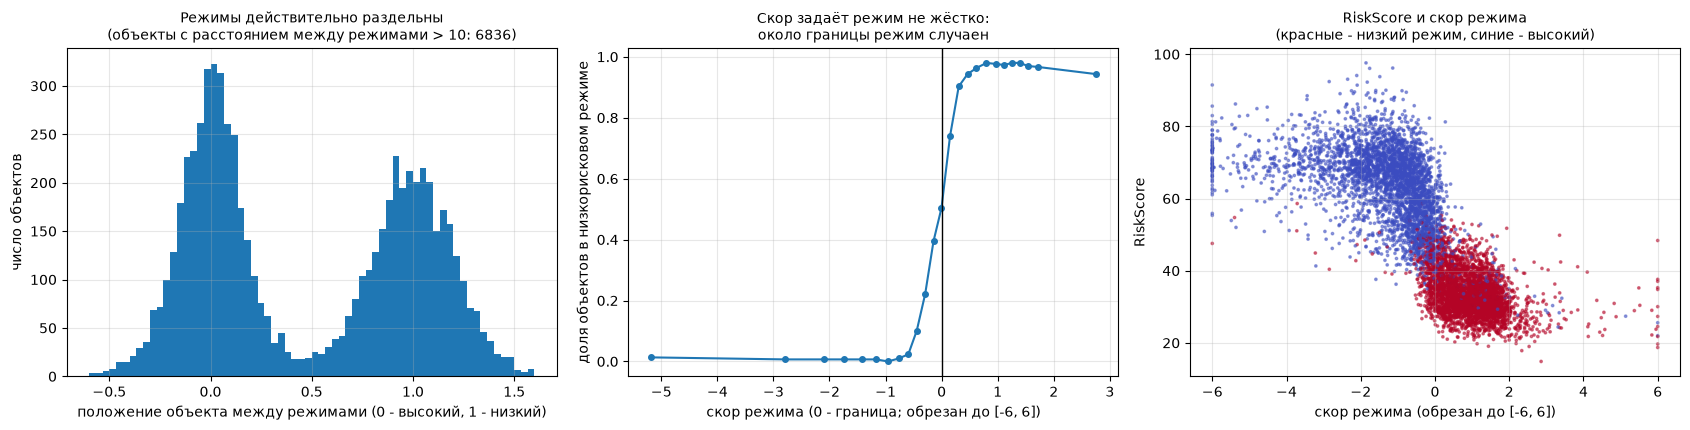

Доля объектов рабочей части в низкорисковом режиме: 0.505
Расстояние между режимами: медиана 14.4, 5% и 95% квантили: [ 9.5 22.5]

Самые большие по модулю веса скора режима (признаки после z-score; плюс - в сторону низкого риска):
InterestRate                     -0.4540
CreditScore                      -0.3600
NetWorth                          0.2910
MonthlyIncome                     0.2870
TotalDebtToIncomeRatio           -0.2070
AnnualIncome                      0.1060
LoanAmount                       -0.1050
LengthOfCreditHistory             0.0860
BankruptcyHistory                -0.0750
EducationLevel=Doctorate          0.0480
max(0, Age - 40)                 -0.0470
LoanPurpose=Debt Consolidation    0.0450


In [36]:
regime_dev = RegimeRegressor().fit(dev, y_dev)
gap = regime_dev.pred_high_ - regime_dev.pred_low_                 # расстояние между режимами для каждого объекта
position = (regime_dev.pred_high_ - y_dev) / gap                   # 0 - объект в высоком режиме, 1 - в низком
clear = gap > 10
score_dev = regime_dev.train_score_

fig, ax = plt.subplots(1, 3, figsize=(17, 4.4))
ax[0].hist(position[clear], bins=66, range=(-0.6, 1.6))
ax[0].set_xlabel("положение объекта между режимами (0 - высокий, 1 - низкий)")
ax[0].set_ylabel("число объектов")
ax[0].set_title(f"Режимы действительно раздельны\n(объекты с расстоянием между режимами > 10: {int(clear.sum())})")

edges = np.quantile(score_dev, np.linspace(0, 1, 26))
group = np.clip(np.searchsorted(edges, score_dev, side="right") - 1, 0, 24)
curve = pd.DataFrame({"s": score_dev, "r": regime_dev.labels_, "g": group}).groupby("g").mean()
ax[1].plot(curve["s"].clip(-6, 6), curve["r"], marker="o", ms=4)
ax[1].axvline(0, color="k", lw=1)
ax[1].set_xlabel("скор режима (0 - граница; обрезан до [-6, 6])")
ax[1].set_ylabel("доля объектов в низкорисковом режиме")
ax[1].set_title("Скор задаёт режим не жёстко:\nоколо границы режим случаен")

sc = ax[2].scatter(np.clip(score_dev, -6, 6), y_dev, c=regime_dev.labels_, s=3, alpha=0.5, cmap="coolwarm")
ax[2].set_xlabel("скор режима (обрезан до [-6, 6])")
ax[2].set_ylabel("RiskScore")
ax[2].set_title("RiskScore и скор режима\n(красные - низкий режим, синие - высокий)")
plt.tight_layout()
plt.show()

print("Доля объектов рабочей части в низкорисковом режиме:", f"{regime_dev.labels_.mean():.3f}")
print("Расстояние между режимами: медиана", f"{np.median(gap):.1f},", "5% и 95% квантили:", np.round(np.quantile(gap, [0.05, 0.95]), 1))
coefs = pd.Series(regime_dev.score_model_.model.coef_ / regime_dev.score_scale_, index=regime_dev.score_feature_names())
print("\nСамые большие по модулю веса скора режима (признаки после z-score; плюс - в сторону низкого риска):")
print(coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(12).round(3).to_string())

Модель разделяет обучающие наблюдения на две группы. Скор зависит главным образом
от ставки, дохода, капитала, долговой нагрузки и рейтинга. Отдельные знаки коэффициентов
нужно трактовать с учётом зависимостей между признаками.

### 9.4. Проверка отдельных решений

На тех же разбиениях сравниваю уточнение меток, переобучение около границы, число узлов,
штраф и использование даты. Отдельно проверяю добавление строк с заполненными пропусками.

In [37]:
variants = {
    "итоговая конфигурация": {},
    "без уточнения меток (только порог 49)": dict(n_label_iter=0),
    "без переобучения скора около границы": dict(n_local=0),
    "скор без месяца заявки и изломов по возрасту": dict(date_age_features=False),
    "6 узлов вместо 10": dict(n_knots=6),
    "L2: alpha = 0.0001": dict(alpha=1e-4),
    "L2: alpha = 0.003": dict(alpha=3e-3),
    "L2: alpha = 0.01": dict(alpha=1e-2),
}
base_name = "E4. E2 + признаки скрытого режима, L2 alpha=0.001"
base_sq = (y_dev - oof_by_experiment[base_name]) ** 2
rows = []
for name, params in variants.items():
    if params:
        oof = oof_predictions(lambda: RegimeRegressor(**params), dev, y_dev, cv_splits)
    else:
        oof = oof_by_experiment[base_name]
    diff = (y_dev - oof) ** 2 - base_sq
    rows.append({"вариант": name, "MSE": mse(y_dev, oof), "разность с итоговой": diff.mean(),
                 "ст. ошибка разности": diff.std() / np.sqrt(len(diff))})
ablation = pd.DataFrame(rows).set_index("вариант")
display(ablation)

,MSE,разность с итоговой,ст. ошибка разности
вариант,,,
итоговая конфигурация,20.0283,0.0000,0.0000
без уточнения меток (только порог 49),22.2213,2.1930,0.2301
без переобучения скора около границы,22.8312,2.8028,0.2309
скор без месяца заявки и изломов по возрасту,20.0423,0.0140,0.0726
6 узлов вместо 10,20.1264,0.0980,0.0572
L2: alpha = 0.0001,20.1863,0.1580,0.0456
L2: alpha = 0.003,20.0325,0.0042,0.0372
L2: alpha = 0.01,20.3811,0.3528,0.0897


In [38]:
# Строки с блоком пропусков: удалить или заполнить (медиана / мода по обучающей части разбиения) и добавить к обучению?
class MedianModeImputer:
    def fit(self, frame):
        self.fill_ = {col: (float(frame[col].median()) if pd.api.types.is_numeric_dtype(frame[col]) else frame[col].mode().iloc[0])
                      for col in frame.columns}
        return self

    def transform(self, frame):
        return frame.fillna(self.fill_)


def cv_mse_with_extra_rows(make_model, extra_rows=None):
    oof = np.full(len(y_dev), np.nan)
    for train_idx, val_idx in cv_splits:
        part, part_y = dev.iloc[train_idx], y_dev[train_idx]
        if extra_rows is not None:
            filled = MedianModeImputer().fit(part).transform(extra_rows)
            part = pd.concat([part, filled], ignore_index=True)
            part_y = np.concatenate([part_y, extra_rows[TARGET].to_numpy(float)])
        oof[val_idx] = make_model().fit(part, part_y).predict(dev.iloc[val_idx])
    return mse(y_dev, oof)


gap_rows = []
for name, make_model in [("E2. кусочно-линейный базис", lambda: RegimeRegressor(use_regime=False)), ("E4. двухрежимная модель", lambda: RegimeRegressor())]:
    gap_rows.append({"модель": name, "строки с пропусками удалены": cv_mse_with_extra_rows(make_model),
                     "заполнены и добавлены к обучению": cv_mse_with_extra_rows(make_model, train_gaps_only)})
print("MSE на кросс-валидации (проверочные блоки одни и те же - только полные строки):")
display(pd.DataFrame(gap_rows).set_index("модель"))

MSE на кросс-валидации (проверочные блоки одни и те же - только полные строки):


,строки с пропусками удалены,заполнены и добавлены к обучению
модель,,
E2. кусочно-линейный базис,26.2212,26.4578
E4. двухрежимная модель,20.0283,20.6210


### 9.5. Распределение ошибок

,доля_объектов,MSE,доля_суммарной_ошибки
zone,,,
|s| <= 0.15,0.0825,70.6778,0.2912
0.15 < |s| <= 0.4,0.1325,47.0275,0.3110
0.4 < |s| <= 1,0.2864,14.0418,0.2008
|s| > 1,0.4987,7.9136,0.1970


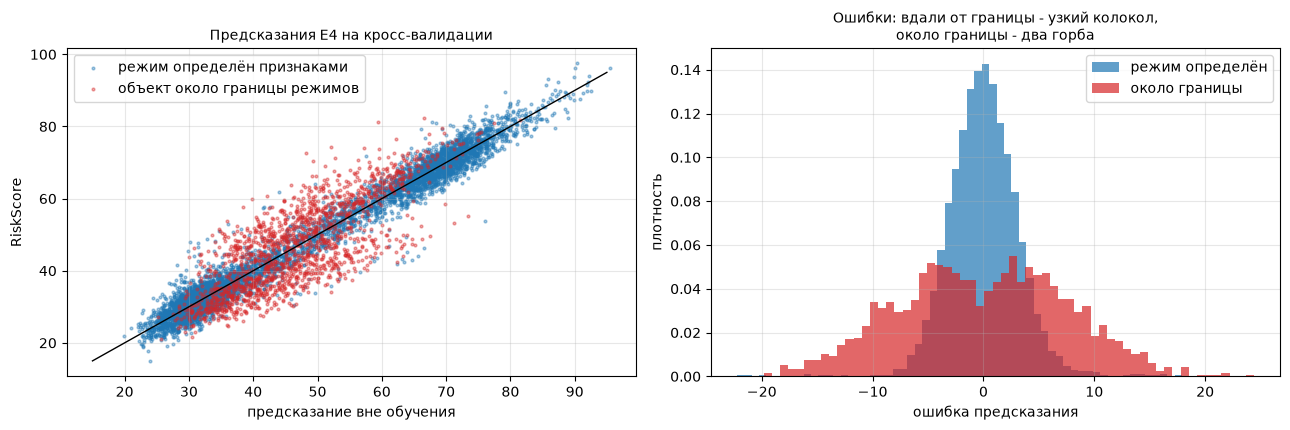

In [39]:
oof_pred = oof_by_experiment[base_name]
oof_score = np.full(len(y_dev), np.nan)
for train_idx, val_idx in cv_splits:                                   # скор режима для объектов вне обучения
    fold_model = RegimeRegressor().fit(dev.iloc[train_idx], y_dev[train_idx])
    oof_score[val_idx] = fold_model.regime_score(dev.iloc[val_idx])

squared_error = (y_dev - oof_pred) ** 2
zone = pd.cut(np.abs(oof_score), [0, 0.15, 0.4, 1.0, np.inf], labels=["|s| <= 0.15", "0.15 < |s| <= 0.4", "0.4 < |s| <= 1", "|s| > 1"],
              include_lowest=True)
anatomy = pd.DataFrame({"zone": zone, "se": squared_error}).groupby("zone", observed=True).agg(
    доля_объектов=("se", lambda v: len(v) / len(squared_error)), MSE=("se", "mean"),
    доля_суммарной_ошибки=("se", lambda v: v.sum() / squared_error.sum()))
display(anatomy)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.4))
near = np.abs(oof_score) <= 0.4
ax[0].scatter(oof_pred[~near], y_dev[~near], s=4, alpha=0.4, label="режим определён признаками")
ax[0].scatter(oof_pred[near], y_dev[near], s=4, alpha=0.4, color="tab:red", label="объект около границы режимов")
ax[0].plot([15, 95], [15, 95], color="k", lw=1)
ax[0].set_xlabel("предсказание вне обучения")
ax[0].set_ylabel("RiskScore")
ax[0].set_title("Предсказания E4 на кросс-валидации")
ax[0].legend()
ax[1].hist(y_dev[~near] - oof_pred[~near], bins=60, alpha=0.7, label="режим определён", density=True)
ax[1].hist(y_dev[near] - oof_pred[near], bins=60, alpha=0.7, color="tab:red", label="около границы", density=True)
ax[1].set_xlabel("ошибка предсказания")
ax[1].set_ylabel("плотность")
ax[1].set_title("Ошибки: вдали от границы - узкий колокол,\nоколо границы - два горба")
ax[1].legend()
plt.tight_layout()
plt.show()

In [40]:
# Можно ли предсказать режим точнее? Ищем, с чем ещё связана «неожиданная» часть метки режима около границы:
# остаток = метка - доля низкого режима при таком же скоре. Проверяются все признаки скора и все их попарные произведения.
labels_dev = regime_dev.labels_
edges = np.quantile(score_dev, np.linspace(0, 1, 31))
group = np.clip(np.searchsorted(edges, score_dev, side="right") - 1, 0, 29)
expected_share = pd.Series(labels_dev).groupby(group).transform("mean").to_numpy()
border = np.abs(score_dev) < 1.0
residual_label = (labels_dev - expected_share)[border]
residual_label = (residual_label - residual_label.mean()) / residual_label.std()

F = ZScoreScaler().fit_transform(regime_dev._score_matrix(dev)[border])
names = regime_dev.score_feature_names()
n_border = len(residual_label)
z_main = F.T @ residual_label / np.sqrt(n_border)
z_pairs = []
for a, b in itertools.combinations_with_replacement(range(F.shape[1]), 2):
    product = F[:, a] * F[:, b]
    spread = product.std()
    if spread > 1e-9:
        z_pairs.append(((product - product.mean()) / spread) @ residual_label / np.sqrt(n_border))
z_pairs = np.array(z_pairs)
print("Объектов около границы режимов (|s| < 1):", n_border)
print("Отдельные признаки: макс. |z| =", f"{np.max(np.abs(z_main)):.2f}", f"({names[int(np.argmax(np.abs(z_main)))]})")
print(f"Попарные произведения ({len(z_pairs)} шт.): макс. |z| =", f"{np.max(np.abs(z_pairs)):.2f};",
      "для чистого шума ожидается максимум около", f"{np.sqrt(2 * np.log(len(z_pairs))):.2f}")

Объектов около границы режимов (|s| < 1): 3733
Отдельные признаки: макс. |z| = 0.88 (LengthOfCreditHistory)
Попарные произведения (1653 шт.): макс. |z| = 3.95; для чистого шума ожидается максимум около 3.85


Большая часть ошибки приходится на наблюдения около границы групп.
Проверка отдельных признаков и их попарных произведений не дала явного улучшения.
Из этого нельзя установить минимально возможный MSE для всего датасета.

## 10. Проверка на отложенной выборке

По кросс-валидации выбираю E4 с десятью узлами и L2 alpha=0,001.
Уточнение меток и переобучение скора около границы дали основной выигрыш.
В итоговом обучении оставляю полные строки: заполнение пропусков ухудшило CV.
Ниже проверяю зафиксированную конфигурацию на сохранённых 1 866 строках.

In [41]:
FINAL_PARAMS = dict(n_knots=10, alpha=1e-3, use_regime=True, start_threshold=49.0, n_label_iter=3, n_local=6, band=0.3,
                    n_score_knots=12, score_clip=6.0, alpha_score=1e-4, date_age_features=True)

holdout_models = {
    "E0. базовый набор": lambda: FeatureModel(BaselineFeatures),
    "E2. кусочно-линейный базис": lambda: RegimeRegressor(use_regime=False),
    "E4. итоговая модель": lambda: RegimeRegressor(**FINAL_PARAMS),
}
holdout_rows, holdout_pred = [], {}
for name, make_model in holdout_models.items():
    model = make_model().fit(dev, y_dev)                    # обучение только на рабочей части
    holdout_pred[name] = model.predict(hold)
    holdout_rows.append({"модель": name, **all_metrics(y_hold, holdout_pred[name])})
holdout_table = pd.DataFrame(holdout_rows).set_index("модель")
print("Отложенная часть:", len(y_hold), "объектов")
display(holdout_table)

final_sq = (y_hold - holdout_pred["E4. итоговая модель"]) ** 2
print("Стандартная ошибка MSE итоговой модели на отложенной части:", f"{final_sq.std() / np.sqrt(len(final_sq)):.2f}")
print("Та же величина для выборки размером с test.csv (5000 объектов):", f"{final_sq.std() / np.sqrt(5000):.2f}")

Отложенная часть: 1866 объектов


,MSE,MAE,R2,MAPE
модель,,,,
E0. базовый набор,50.9707,5.7184,0.8271,0.1359
E2. кусочно-линейный базис,24.4358,3.7512,0.9171,0.0884
E4. итоговая модель,19.2772,3.1377,0.9346,0.0727


Стандартная ошибка MSE итоговой модели на отложенной части: 0.96
Та же величина для выборки размером с test.csv (5000 объектов): 0.59


## 11. Leave-one-out

LOO выполняю на всей рабочей части из 7 466 строк для базовой линейной регрессии.
Средние, масштабы и ковариации каждого разбиения восстанавливаются вычитанием вклада
исключённого объекта из общих сумм. Итоговые метрики считаю по всему вектору предсказаний.

Для проверки сравниваю результат с прямым LOO на 1 000 строках и со sklearn.
Формула через рычаги дополнительно проверяется для МНК без штрафа и отбора признаков.

In [42]:
def loo_predictions_least_squares(X, y):
    """Точный LOO для схемы «z-score + МНК со свободным членом».

    Для каждого объекта i статистики остальных n-1 объектов получаются вычитанием вклада объекта i из сумм по всей выборке,
    затем заново считаются средние, стандартные отклонения и решается задача МНК для стандартизованных признаков.
    """
    X = np.asarray(X, dtype=float)
    y = np.asarray(y, dtype=float)
    n, d = X.shape
    # Численная предобработка: общий сдвиг и масштаб столбцов. На результат не влияет, потому что z-score внутри разбиения
    # не меняется при аффинной замене признака; нужна только для того, чтобы суммы квадратов считались без потери точности.
    Z = ZScoreScaler().fit_transform(X)
    y_shift = y.mean()
    t = y - y_shift
    sum_z, sum_zz, sum_zt, sum_t = Z.sum(axis=0), Z.T @ Z, Z.T @ t, t.sum()
    m = n - 1
    predictions = np.empty(n)
    for i in range(n):
        zi, ti = Z[i], t[i]
        mean = (sum_z - zi) / m                                          # средние по n-1 объектам
        cov = (sum_zz - np.outer(zi, zi)) / m - np.outer(mean, mean)     # ковариации признаков по n-1 объектам
        t_mean = (sum_t - ti) / m
        cov_t = (sum_zt - zi * ti) / m - mean * t_mean                   # ковариации признаков с целью
        std = np.sqrt(np.diag(cov))
        std = np.where(std > 0, std, 1.0)
        gram = cov / np.outer(std, std)                                  # X^T X / m после z-score внутри разбиения
        w = np.linalg.lstsq(gram, cov_t / std, rcond=None)[0]            # нормальные уравнения, устойчиво к вырожденности
        predictions[i] = y_shift + t_mean + ((zi - mean) / std) @ w
    return predictions


# --- LOO по всей рабочей части
t0 = time.time()
loo_pred = loo_predictions_least_squares(X_dev, y_dev)
loo_time = time.time() - t0
print(f"LOO по всем {len(y_dev)} объектам рабочей части: {loo_time:.1f} c")
display(pd.DataFrame({"LOO (все объекты)": all_metrics(y_dev, loo_pred),
                      "5-fold (среднее по разбиениям)": base_folds.mean().to_dict(),
                      "5-fold (по всему вектору)": all_metrics(y_dev, base_oof)}))

LOO по всем 7466 объектам рабочей части: 4.2 c


,LOO (все объекты),5-fold (среднее по разбиениям),5-fold (по всему вектору)
MSE,50.8264,50.7858,50.7859
MAE,5.7146,5.7180,5.7180
R2,0.8294,0.8293,0.8295
MAPE,0.1341,0.1342,0.1342


In [43]:
# Проверка 1: универсальный LOO «в лоб» (собственный класс, n обучений) на подвыборке из 1000 объектов
sub = np.sort(np.random.default_rng(SEED).choice(len(y_dev), size=1000, replace=False))
t0 = time.time()
brute_sub = oof_predictions(lambda: ScaledLinearModel(), X_dev[sub], y_dev[sub], loo_indices(len(sub)))
brute_time = time.time() - t0
fast_sub = loo_predictions_least_squares(X_dev[sub], y_dev[sub])
print(f"Подвыборка 1000 объектов: универсальный LOO ({brute_time:.1f} c) и специализированная функция расходятся не более чем на",
      f"{np.max(np.abs(brute_sub - fast_sub)):.1e}")

# Проверка 2: формула e_loo_i = e_i / (1 - h_ii) на всей рабочей части. Предпосылки формулы: обычный МНК без штрафа и без отбора
# признаков, зависящего от данных; нормализация внутри разбиения не мешает, так как предсказания МНК не меняются
# при линейном перемасштабировании признаков.
A = np.column_stack([np.ones(len(y_dev)), ZScoreScaler().fit_transform(X_dev)])
U, s, _ = np.linalg.svd(A, full_matrices=False)
U = U[:, s > s.max() * max(A.shape) * np.finfo(float).eps]
leverage = np.sum(U ** 2, axis=1)
residual = y_dev - U @ (U.T @ y_dev)
loo_by_formula = y_dev - residual / (1.0 - leverage)
print("Вся рабочая часть: макс. рычаг h_ii =", f"{leverage.max():.3f};", "макс. |разность| LOO и формулы через рычаги:",
      f"{np.max(np.abs(loo_pred - loo_by_formula)):.1e}")

# Проверка 3: sklearn.LeaveOneOut на той же подвыборке и с той же обработкой
sk_sub = cross_val_predict(make_pipeline(SkStandardScaler(), SkLinearRegression()), X_dev[sub], y_dev[sub], cv=LeaveOneOut())
print("Подвыборка 1000 объектов: макс. |разность| собственного LOO и sklearn.LeaveOneOut:", f"{np.max(np.abs(brute_sub - sk_sub)):.1e}")
print("Метрики LOO на подвыборке (другая задача: обучение на 999 объектах):",
      {k: round(v, 4) for k, v in all_metrics(y_dev[sub], brute_sub).items()})

Подвыборка 1000 объектов: универсальный LOO (2.1 c) и специализированная функция расходятся не более чем на 6.8e-12
Вся рабочая часть: макс. рычаг h_ii = 0.283; макс. |разность| LOO и формулы через рычаги: 3.1e-12


Подвыборка 1000 объектов: макс. |разность| собственного LOO и sklearn.LeaveOneOut: 1.1e-13
Метрики LOO на подвыборке (другая задача: обучение на 999 объектах): {'MSE': 52.8923, 'MAE': 5.8511, 'R2': 0.8292, 'MAPE': 0.1344}


Проверены размеры и покрытие k-fold, воспроизводимость разбиений и совпадение со sklearn.
Специализированный LOO сопоставлен с прямым переобучением и формулой для МНК.
Это проверка базовой модели, а не итоговой модели со скрытыми группами.

## 12. Финальное обучение и файл посылки

Обучаю E4 на всех 9 332 полных строках после очистки и предсказываю `RiskScore` для test.
Проверяю число строк, столбцы `ID,RiskScore`, порядок идентификаторов и конечность значений.
Предсказания сохраняю без ограничения диапазона и округления.

In [44]:
final_model = RegimeRegressor(**FINAL_PARAMS).fit(train, y_all)
test_pred = final_model.predict(test_raw)

submission = pd.DataFrame({"ID": test_raw["ID"].to_numpy(), "RiskScore": test_pred})

# --- проверки файла
assert list(submission.columns) == list(example.columns) == ["ID", "RiskScore"], "имена или порядок столбцов"
assert len(submission) == len(test_raw) == len(example), "число строк"
assert (submission["ID"].to_numpy() == example["ID"].to_numpy()).all(), "ID должны совпадать с ex.csv и идти в том же порядке"
assert submission["ID"].is_unique
assert np.issubdtype(submission["RiskScore"].dtype, np.floating), "предсказания должны быть вещественными"
assert np.isfinite(submission["RiskScore"]).all(), "в предсказаниях есть пропуски или бесконечности"

OUTPUT_PATH = "submission.csv"
submission.to_csv(OUTPUT_PATH, index=False)

written = pd.read_csv(OUTPUT_PATH)
assert list(written.columns) == ["ID", "RiskScore"] and len(written) == len(test_raw)
assert np.allclose(written["RiskScore"].to_numpy(), test_pred) and (written["ID"].to_numpy() == test_raw["ID"].to_numpy()).all()
with open(OUTPUT_PATH, encoding="utf-8") as handle:
    first_lines = [next(handle).rstrip("\n") for _ in range(4)]

print("Файл сохранён:", OUTPUT_PATH, "(в текущей рабочей папке)")
print("Строк:", len(written), "| столбцы:", list(written.columns), "| пропусков:", int(written.isna().sum().sum()))
print("Первые строки файла:", first_lines)
print("\nПредсказания для test:  min", f"{test_pred.min():.2f},", "среднее", f"{test_pred.mean():.2f},", "max", f"{test_pred.max():.2f}")
print("Цель в train:           min", f"{y_all.min():.2f},", "среднее", f"{y_all.mean():.2f},", "max", f"{y_all.max():.2f}")
test_score = final_model.regime_score(test_raw)
print("Доля объектов около границы режимов (|s| <= 0.4):  test", f"{np.mean(np.abs(test_score) <= 0.4):.3f}",
      "| train", f"{np.mean(np.abs(final_model.train_score_) <= 0.4):.3f}")
display(submission.head(10))

Файл сохранён: submission.csv (в текущей рабочей папке)
Строк: 5000 | столбцы: ['ID', 'RiskScore'] | пропусков: 0
Первые строки файла: ['ID,RiskScore', '0,32.83709702811831', '1,54.65101279951162', '2,29.98649718100863']

Предсказания для test:  min 20.61, среднее 48.19, max 95.01
Цель в train:           min 14.84, среднее 48.31, max 97.60
Доля объектов около границы режимов (|s| <= 0.4):  test 0.204 | train 0.213


,ID,RiskScore
0,0,32.8371
1,1,54.6510
2,2,29.9865
3,3,34.3448
4,4,31.9234
5,5,69.4138
6,6,30.7847
7,7,31.2594
8,8,32.9758
9,9,61.9467


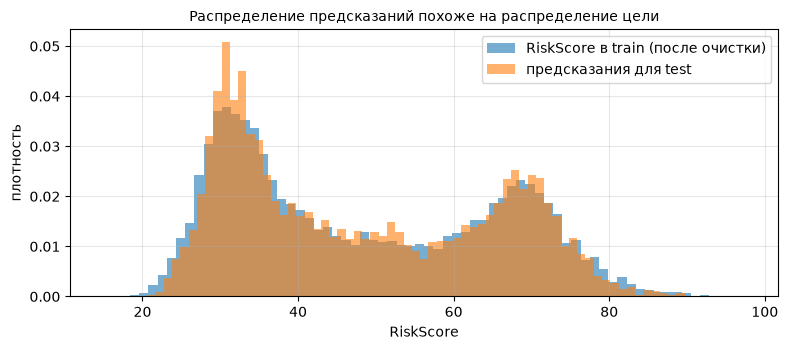

In [45]:
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.hist(y_all, bins=70, alpha=0.6, density=True, label="RiskScore в train (после очистки)")
ax.hist(test_pred, bins=70, alpha=0.6, density=True, label="предсказания для test")
ax.set_xlabel("RiskScore")
ax.set_ylabel("плотность")
ax.set_title("Распределение предсказаний похоже на распределение цели")
ax.legend()
plt.tight_layout()
plt.show()

## 13. Итоги

In [46]:
summary_rows = [
    ("E0. базовая модель, 5-fold на рабочей части", results.loc["E0. базовый набор"]),
    ("E4. итоговая модель, 5-fold на рабочей части", results.loc[base_name]),
]
final_summary = pd.DataFrame({name: row[["MSE", "MAE", "R2", "MAPE"]] for name, row in summary_rows}).T.astype(float)
final_summary.loc["E0. базовая модель, LOO на рабочей части"] = pd.Series(all_metrics(y_dev, loo_pred))
final_summary.loc["E4. итоговая модель, отложенная часть (одна проверка)"] = holdout_table.loc["E4. итоговая модель"]
print("Сводка локальных оценок (MAPE - доля, не проценты):")
display(final_summary)

Сводка локальных оценок (MAPE - доля, не проценты):


,MSE,MAE,R2,MAPE
"E0. базовая модель, 5-fold на рабочей части",50.7858,5.7180,0.8293,0.1342
"E4. итоговая модель, 5-fold на рабочей части",20.0282,3.1932,0.9327,0.0740
"E0. базовая модель, LOO на рабочей части",50.8264,5.7146,0.8294,0.1341
"E4. итоговая модель, отложенная часть (одна проверка)",19.2772,3.1377,0.9346,0.0727


Логарифмы и кусочно-линейные признаки улучшили базовую регрессию.
Дальнейший выигрыш дала модель со скрытыми группами: CV MSE около 20,03,
MSE на отложенной части около 19,28. Для этой посылки получен Kaggle MSE около 20,01.

Собственные нормализации, метрики, способы обучения и регуляризации сравнены со sklearn.
Основные значения и результаты проверок приведены в таблицах выше.

Список категорий зафиксирован по всей очищенной train-таблице; сама модель, нормализация
и узлы обучаются внутри каждого фолда. Структура цели изучалась до оформления ноутбука
на всей обучающей таблице, поэтому отложенная оценка может быть оптимистичной.
Модель многоэтапная и используется здесь как отдельный эксперимент.

### Выполненные пункты

| Пункт | Раздел |
|---|---|
| EDA, графики, статистики и выводы | 1–2 |
| Собственные z-score и min-max | 4 |
| Аналитическое решение, GD и SGD | 5 |
| Собственные k-fold и LOO | 7, 11 |
| MSE, MAE, R², MAPE: формулы и сравнения | 3 |
| Дополнительно: L1, L2, L1+L2 | 8 |
| Дополнительно: Lp с задаваемым p | 8 |
| Эксперимент со скрытыми группами и сравнение вариантов | 9–10 |
| Финальное обучение и submission.csv | 12 |
